| Setting | Proposed setup |
|---|---|
| Models | Qwen2.5-0.5B-Instruct; Gemma3-1B-it |
| Inference precision | Qwen: FP16; Gemma: FP32 |
| Changed variants per model | One LoRA fine-tune, Gaussian noise, magnitude pruning, random pruning |
| Total model versions | 2 unchanged + 8 changed |
| Prompts per detection | 1, 3, 5, 10 |
| Samples per prompt per detection | 1, 3, 10, 20, 50 |
| Reference samples per prompt | 50 |

Step 1 — Mount Drive and create a separate experiment folder

In [ ]:
from google.colab import drive
from pathlib import Path
import json
import subprocess

drive.mount("/content/drive")

SAVE_DIR = Path("/content/drive/MyDrive/B3IT_Figure1_TwoModels")

for folder in ["code", "configs", "data", "checkpoints", "results", "plots", "logs"]:
    (SAVE_DIR / folder).mkdir(parents=True, exist_ok=True)

# Verify that Drive is writable.
test_file = SAVE_DIR / "configs" / "drive_write_test.txt"
test_file.write_text("Drive storage verified.\n")
assert test_file.read_text() == "Drive storage verified.\n"

plan = {
    "figure": 1,
    "models": {
        "Qwen/Qwen2.5-0.5B-Instruct": {"inference_dtype": "float16"},
        "google/gemma-3-1b-it": {"inference_dtype": "float32"}
    },
    "perturbation_types": [
        "lora_finetuning",
        "gaussian_noise",
        "magnitude_pruning",
        "random_pruning"
    ],
    "variants_per_model": 4,
    "perturbation_strengths": "Pending original-code verification",
    "prompt_counts": [1, 3, 5, 10],
    "detection_samples_per_prompt": [1, 3, 10, 20, 50],
    "reference_samples_per_prompt": 50,
    "scope": "Reduced reproduction with adapted numerical precision"
}

plan_path = SAVE_DIR / "configs" / "experiment_plan.json"

# Avoid overwriting an existing plan when resuming.
if not plan_path.exists():
    plan_path.write_text(json.dumps(plan, indent=2))

print("Drive write check passed.")
print("Experiment directory:", SAVE_DIR)
print("Experiment plan:", plan_path)

gpu = subprocess.run(
    ["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
    capture_output=True,
    text=True
)
print("\nGPU:", gpu.stdout.strip() or gpu.stderr.strip())
assert gpu.returncode == 0, "Enable a GPU runtime before continuing."

Mounted at /content/drive
Drive write check passed.
Experiment directory: /content/drive/MyDrive/B3IT_Figure1_TwoModels
Experiment plan: /content/drive/MyDrive/B3IT_Figure1_TwoModels/configs/experiment_plan.json

GPU: Tesla T4, 15360 MiB


Step 2 — Clone the original repository and save its exact version

In [ ]:
from pathlib import Path
import subprocess
import json

SAVE_DIR = Path("/content/drive/MyDrive/B3IT_Figure1_TwoModels")
REPO_DIR = Path("/content/b3it-figure1")
PROJECT_DIR = REPO_DIR / "track-llm-apis"

def run_command(args, cwd=None):
    result = subprocess.run(
        args, cwd=cwd, capture_output=True, text=True
    )
    if result.returncode != 0:
        print(result.stdout)
        print(result.stderr)
        raise RuntimeError(f"Command failed: {args[0]}")
    return result.stdout.strip()

if not REPO_DIR.exists():
    print("Cloning repository...")
    run_command([
        "git", "clone",
        "https://github.com/timothee-chauvin/token-efficient-change-detection-llm-apis.git",
        str(REPO_DIR)
    ])
else:
    assert (REPO_DIR / ".git").exists(), (
        "The destination exists but is not a Git checkout."
    )
    print("Existing checkout found; keeping it unchanged.")

assert (PROJECT_DIR / "pyproject.toml").exists()
assert (PROJECT_DIR / "src" / "track_llm_apis").is_dir()

commit = run_command(["git", "rev-parse", "HEAD"], cwd=REPO_DIR)
status = run_command(["git", "status", "--porcelain"], cwd=REPO_DIR)

# Save the committed original source, independently of future local edits.
archive_path = SAVE_DIR / "code" / f"original_source_{commit[:12]}.tar.gz"

if not archive_path.exists():
    temporary_archive = archive_path.with_suffix(".tmp")
    run_command([
        "git", "archive",
        "--format=tar.gz",
        f"--output={temporary_archive}",
        commit
    ], cwd=REPO_DIR)
    temporary_archive.replace(archive_path)

assert archive_path.stat().st_size > 0

metadata = {
    "repository": run_command(
        ["git", "remote", "get-url", "origin"], cwd=REPO_DIR
    ),
    "commit": commit,
    "original_source_archive": str(archive_path),
}

metadata_path = SAVE_DIR / "configs" / f"repository_{commit[:12]}.json"
metadata_path.write_text(json.dumps(metadata, indent=2))

print("\nRepository verification passed.")
print("Project:", PROJECT_DIR)
print("Commit:", commit)
print("Working tree:", "Clean" if not status else status)
print("Original source backed up:", archive_path)

Cloning repository...

Repository verification passed.
Project: /content/b3it-figure1/track-llm-apis
Commit: ad2f69295797a5f03e7b480246080d91087d9007
Working tree: Clean
Original source backed up: /content/drive/MyDrive/B3IT_Figure1_TwoModels/code/original_source_ad2f69295797.tar.gz


Step 3 — Inspect dependencies before installation

In [ ]:
from pathlib import Path
import tomllib

PROJECT_DIR = Path("/content/b3it-figure1/track-llm-apis")
SAVE_DIR = Path("/content/drive/MyDrive/B3IT_Figure1_TwoModels")

pyproject_path = PROJECT_DIR / "pyproject.toml"
assert pyproject_path.exists(), "Repository configuration is missing."

raw_config = pyproject_path.read_text()
config = tomllib.loads(raw_config)
project = config.get("project", {})

print("Required Python:", project.get("requires-python", "Not specified"))

print("\nProject dependencies:")
for dependency in project.get("dependencies", []):
    print(" -", dependency)

print("\nDependency groups:")
print(config.get("dependency-groups", {}))

print("\nUV configuration:")
print(config.get("tool", {}).get("uv", {}))

print("\nDependency/environment files:")
for name in ["uv.lock", ".python-version", "requirements.txt"]:
    path = PROJECT_DIR / name
    print(f"{name}: {'present' if path.exists() else 'absent'}")
    if name == ".python-version" and path.exists():
        print("Python version:", path.read_text().strip())

# Save the inspected configuration to Drive.
backup = SAVE_DIR / "configs" / "original_pyproject.toml"
if backup.exists():
    assert backup.read_text() == raw_config, (
        "Saved configuration differs; report this before proceeding."
    )
else:
    backup.write_text(raw_config)

print("\nDependency inspection completed and configuration backed up.")

Required Python: >=3.11

Project dependencies:
 - aiohttp>=3.11.18
 - beartype>=0.21.0
 - datasets>=3.6.0
 - fire>=0.7.0
 - frozendict>=2.4.6
 - frozenlist>=1.6.0
 - jaxtyping>=0.3.2
 - kaleido>=1.1.0
 - lightning>=2.5.2
 - matplotlib>=3.10.3
 - numpy>=2.2.6
 - nvidia-modelopt[hf]>=0.33.0
 - openai>=1.78.1
 - orjson>=3.11.3
 - peft>=0.16.0
 - plotly>=6.1.1
 - pydantic-settings>=2.10.1
 - python-dotenv>=1.1.0
 - rapidgzip>=0.15.2
 - requests>=2.32.3
 - scikit-learn>=1.7.1
 - scipy<=1.15.3
 - statsmodels>=0.14.4
 - torch>=2.7.1
 - tqdm>=4.67.1
 - transformers>=4.53.1
 - vllm>=0.10.0
 - vulture>=2.14
 - xxhash>=3.5.0

Dependency groups:
{'dev': ['microsoft-python-type-stubs', 'pre-commit>=4.2.0', 'pyright>=1.1.403', 'pytest>=8.4.1', 'pytest-env>=1.1.5', 'ruff>=0.11.9']}

UV configuration:
{'sources': {'microsoft-python-type-stubs': {'git': 'https://github.com/microsoft/python-type-stubs.git'}}}

Dependency/environment files:
uv.lock: present
.python-version: present
Python version: 3.11
r

Step 4 — Install the project dependencies

In [ ]:
%pip install -q uv

from pathlib import Path
import subprocess
import shutil
import os

PROJECT_DIR = Path("/content/b3it-figure1/track-llm-apis")
SAVE_DIR = Path("/content/drive/MyDrive/B3IT_Figure1_TwoModels")

uv_path = shutil.which("uv")
assert uv_path, "uv installation failed."

# Prevent the earlier Colab matplotlib and CUDA subprocess problems.
os.environ["MPLBACKEND"] = "Agg"
os.environ["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"

log_path = SAVE_DIR / "logs" / "dependency_install.log"

print("Installing locked dependencies. Wait until this cell finishes...")

with log_path.open("w") as log:
    process = subprocess.Popen(
        [
            uv_path, "sync",
            "--frozen",
            "--no-dev",
            "--python", "3.11",
        ],
        cwd=PROJECT_DIR,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )

    for line in process.stdout:
        print(line, end="")
        log.write(line)
        log.flush()

    return_code = process.wait()

assert return_code == 0, (
    f"Installation failed. Share the final error lines. Log: {log_path}"
)

PYTHON = str(PROJECT_DIR / ".venv" / "bin" / "python")
assert Path(PYTHON).exists()

# Record installed versions for reproducibility.
result = subprocess.run(
    [uv_path, "pip", "freeze", "--python", PYTHON],
    capture_output=True,
    text=True,
    check=True,
)

(SAVE_DIR / "configs" / "installed_packages.txt").write_text(
    result.stdout
)

print("\nDependencies installed successfully.")
print("Experiment Python:", PYTHON)
print("Package versions and installation log saved to Drive.")

Installing locked dependencies. Wait until this cell finishes...


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/B3IT_Figure1_TwoModels/logs/dependency_install.log'

Step 5 — Verify the environment and GPU

In [ ]:
from pathlib import Path
import os
import subprocess

PROJECT_DIR = Path("/content/b3it-figure1/track-llm-apis")
SAVE_DIR = Path("/content/drive/MyDrive/B3IT_Figure1_TwoModels")
PYTHON = str(PROJECT_DIR / ".venv" / "bin" / "python")

os.environ["MPLBACKEND"] = "Agg"
os.environ["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"

# Make tools installed inside the virtual environment discoverable.
venv_bin = str(PROJECT_DIR / ".venv" / "bin")
if venv_bin not in os.environ["PATH"].split(os.pathsep):
    os.environ["PATH"] = venv_bin + os.pathsep + os.environ["PATH"]

check_code = r'''
import sys
import shutil
import importlib.metadata as metadata
import torch
import transformers
import lightning
import peft
import vllm
import track_llm_apis

print("Python:", sys.version.split()[0])
for package in ["torch", "transformers", "vllm", "lightning", "peft"]:
    print(f"{package}: {metadata.version(package)}")

assert torch.cuda.is_available(), "CUDA is unavailable."
properties = torch.cuda.get_device_properties(0)

print("GPU:", properties.name)
print("GPU memory (GiB):", round(properties.total_memory / 1024**3, 1))
print("Compute capability:", torch.cuda.get_device_capability(0))
print(
    "Native BF16 support:",
    torch.cuda.is_bf16_supported(including_emulation=False)
)

for dtype in [torch.float16, torch.float32]:
    x = torch.ones((32, 32), device="cuda", dtype=dtype)
    y = x @ x
    torch.cuda.synchronize()
    assert torch.isfinite(y).all().item()
    assert (y == 32).all().item()
    print(f"{dtype}: GPU calculation passed.")
    del x, y

assert shutil.which("ninja"), "ninja is not available on PATH."
print("ninja:", shutil.which("ninja"))
print("Project import:", track_llm_apis.__file__)
print("Environment check passed.")
'''

result = subprocess.run(
    [PYTHON, "-u", "-c", check_code],
    cwd=PROJECT_DIR,
    env=os.environ.copy(),
    capture_output=True,
    text=True,
)

print(result.stdout)
if result.stderr:
    print(result.stderr)
print("Exit code:", result.returncode)

log_path = SAVE_DIR / "logs" / "environment_check.log"
log_path.write_text(
    result.stdout + "\n" + result.stderr
    + f"\nExit code: {result.returncode}\n"
)

assert result.returncode == 0, "Environment check failed; share the output."

Python: 3.11.18
torch: 2.9.1
transformers: 4.57.6
vllm: 0.15.0
lightning: 2.6.1
peft: 0.18.1
GPU: Tesla T4
GPU memory (GiB): 14.6
Compute capability: (7, 5)
Native BF16 support: False
torch.float16: GPU calculation passed.
torch.float32: GPU calculation passed.
ninja: /content/b3it-figure1/track-llm-apis/.venv/bin/ninja
Project import: /content/b3it-figure1/track-llm-apis/src/track_llm_apis/__init__.py
Environment check passed.

Exit code: 0


Step 6 — Verify access to both models and LMSYS

In [ ]:
from google.colab import userdata
import os
import subprocess

token = userdata.get("HF_TOKEN")
assert token, "Add HF_TOKEN to Colab Secrets and enable notebook access."

# Pass credentials to the subprocess without saving them to Drive.
os.environ["HF_TOKEN"] = token

access_code = r'''
from huggingface_hub import hf_hub_download, HfApi

for model in [
    "Qwen/Qwen2.5-0.5B-Instruct",
    "google/gemma-3-1b-it",
]:
    hf_hub_download(
        repo_id=model,
        filename="config.json",
    )
    print(f"Model configuration access verified: {model}", flush=True)

# Test access to actual dataset bytes without downloading the full dataset.
api = HfApi()
dataset_id = "lmsys/lmsys-chat-1m"

files = api.list_repo_files(dataset_id, repo_type="dataset")
parquet_files = sorted(f for f in files if f.endswith(".parquet"))
assert parquet_files, "No LMSYS parquet files found."

from huggingface_hub import hf_hub_url
import os
import requests

url = hf_hub_url(
    repo_id=dataset_id,
    filename=parquet_files[0],
    repo_type="dataset",
)

with requests.get(
    url,
    headers={
        "Authorization": f"Bearer {os.environ['HF_TOKEN']}",
        "Range": "bytes=0-3",
    },
    stream=True,
    timeout=60,
) as response:
    # Avoid printing signed download URLs or credentials.
    assert response.status_code in (200, 206), (
        f"LMSYS access failed with HTTP {response.status_code}. "
        "Check dataset access and token permissions."
    )
    prefix = next(response.iter_content(chunk_size=4), b"")
    assert prefix == b"PAR1", "Unexpected dataset file header."

print("LMSYS dataset download access verified.")
print("Access checks passed.")
'''

result = subprocess.run(
    [PYTHON, "-u", "-c", access_code],
    cwd=PROJECT_DIR,
    env=os.environ.copy(),
    capture_output=True,
    text=True,
)

print(result.stdout)
if result.returncode:
    print(result.stderr)
print("Exit code:", result.returncode)

# Save only successful check messages, never the token.
if result.returncode == 0:
    (SAVE_DIR / "logs" / "access_check.log").write_text(result.stdout)

assert result.returncode == 0, "Access check failed; share the error."

Model configuration access verified: Qwen/Qwen2.5-0.5B-Instruct
Model configuration access verified: google/gemma-3-1b-it
LMSYS dataset download access verified.
Access checks passed.

Exit code: 0


Step 7 — Inspect the exact functions we need to change

In [ ]:
import subprocess

inspection_code = r'''
import ast
from pathlib import Path
from importlib.util import find_spec

project = Path("/content/b3it-figure1/track-llm-apis")

def show_function(path, function_name):
    assert path.exists(), f"File missing: {path}"
    source = path.read_text()
    tree = ast.parse(source)
    lines = source.splitlines()

    matches = [
        node for node in ast.walk(tree)
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
        and node.name == function_name
    ]

    print(f"\nFILE: {path}")
    if not matches:
        print(f"Function {function_name} not found; report this output.")
        return

    for node in matches:
        start = min(
            [node.lineno]
            + [decorator.lineno for decorator in node.decorator_list]
        )
        print(f"FUNCTION: {function_name}")
        for index in range(start - 1, node.end_lineno):
            print(f"{index + 1:4}: {lines[index]}")

show_function(
    project / "src/track_llm_apis/sampling/vllm_sampling.py",
    "init_vllm_bi",
)

spec = find_spec("vllm")
assert spec and spec.submodule_search_locations, "vLLM package not found."
vllm_dir = Path(next(iter(spec.submodule_search_locations)))

show_function(
    vllm_dir / "v1/attention/ops/triton_unified_attention.py",
    "_get_tile_size",
)
'''

result = subprocess.run(
    [PYTHON, "-u", "-c", inspection_code],
    cwd=PROJECT_DIR,
    capture_output=True,
    text=True,
)

print(result.stdout)
if result.stderr:
    print(result.stderr)

assert result.returncode == 0, "Inspection failed; share the error."

(SAVE_DIR / "logs" / "original_function_inspection.txt").write_text(
    result.stdout
)

print("Inspection saved to Drive. No source files changed.")


FILE: /content/b3it-figure1/track-llm-apis/src/track_llm_apis/sampling/vllm_sampling.py
FUNCTION: init_vllm_bi
 268: def init_vllm_bi(model_name: str, device: str) -> LLM:
 269:     """Initialize vLLM for BI phase 1."""
 270:     assert device == "cuda" or (device.startswith("cuda:") and device[5:].isdigit())
 271: 
 272:     available_memory_fraction = available_gpu_memory_fraction()
 273:     vllm_memory = 0.9 * available_memory_fraction
 274:     llm = LLM(
 275:         model=model_name,
 276:         enforce_eager=True,
 277:         gpu_memory_utilization=vllm_memory,
 278:     )
 279:     return llm

FILE: /content/b3it-figure1/track-llm-apis/.venv/lib/python3.11/site-packages/vllm/v1/attention/ops/triton_unified_attention.py
FUNCTION: _get_tile_size
 860: def _get_tile_size(
 861:     head_size: int,
 862:     sliding_window: int,
 863:     element_size: int,
 864:     is_prefill: bool,
 865: ) -> int:
 866:     """Select tile size with Gemma3-specific optimization.
 867: 
 86

Step 8 — Apply and back up the T4 compatibility changes

In [ ]:
from pathlib import Path
import ast
import subprocess
import textwrap
import difflib
import json

source_path = (
    PROJECT_DIR / "src/track_llm_apis/sampling/vllm_sampling.py"
)

# Locate vLLM inside the experiment environment.
location = subprocess.run(
    [
        PYTHON, "-c",
        "from importlib.util import find_spec; "
        "print(next(iter(find_spec('vllm').submodule_search_locations)))"
    ],
    capture_output=True,
    text=True,
    check=True,
)

kernel_path = (
    Path(location.stdout.strip())
    / "v1/attention/ops/triton_unified_attention.py"
)

new_initializer = textwrap.dedent('''\
def init_vllm_bi(model_name: str, device: str) -> LLM:
    """Initialize BI inference for the two-model T4 experiment."""
    from transformers import AutoConfig

    assert device in ("cuda", "cuda:0"), (
        "This experiment is configured for one GPU."
    )

    # Reading model configuration also works for saved variant checkpoints.
    model_config = AutoConfig.from_pretrained(model_name)
    model_type = model_config.model_type

    if model_type == "gemma3_text":
        inference_dtype = "float32"
    elif model_type == "qwen2":
        inference_dtype = "float16"
    else:
        raise ValueError(f"Unexpected model architecture: {model_type}")

    available_memory_fraction = available_gpu_memory_fraction()
    vllm_memory = min(0.70, 0.9 * available_memory_fraction)

    return LLM(
        model=model_name,
        dtype=inference_dtype,
        max_model_len=1024,
        max_num_seqs=64,
        enforce_eager=True,
        enable_prefix_caching=False,
        gpu_memory_utilization=vllm_memory,
        seed=0,
    )
''')

def replace_function(source, name, replacement):
    tree = ast.parse(source)
    matches = [
        node for node in tree.body
        if isinstance(node, ast.FunctionDef) and node.name == name
    ]
    assert len(matches) == 1, f"Expected exactly one {name} function."
    node = matches[0]
    lines = source.splitlines(keepends=True)

    # Preserve decorators, if present.
    return (
        "".join(lines[:node.lineno - 1])
        + replacement
        + "".join(lines[node.end_lineno:])
    )

source_before = source_path.read_text()
source_after = replace_function(
    source_before, "init_vllm_bi", new_initializer
)

kernel_before = kernel_path.read_text()
marker = "    # B3IT T4: smaller attention tile for Gemma FP32.\n"
anchor = "    if _is_gemma3_attention(head_size, sliding_window):\n"

if marker in kernel_before:
    kernel_after = kernel_before
else:
    assert kernel_before.count(anchor) == 1, (
        "Unexpected kernel source; stop and report this."
    )
    kernel_after = kernel_before.replace(
        anchor,
        marker
        + "    if element_size == 4 and "
          "_is_gemma3_attention(head_size, sliding_window):\n"
        + "        return 16\n\n"
        + anchor,
        1,
    )

# Validate both edits before writing either file.
compile(source_after, str(source_path), "exec")
compile(kernel_after, str(kernel_path), "exec")

backup_dir = SAVE_DIR / "code" / "t4_compatibility"
backup_dir.mkdir(parents=True, exist_ok=True)

changes = [
    ("vllm_sampling", source_path, source_before, source_after),
    ("triton_unified_attention", kernel_path, kernel_before, kernel_after),
]

for label, path, before, after in changes:
    original_backup = backup_dir / f"{label}.original.py"
    if not original_backup.exists():
        original_backup.write_text(before)

    path.write_text(after)
    assert path.read_text() == after

    (backup_dir / f"{label}.patched.py").write_text(after)

    original = original_backup.read_text()
    diff = "".join(difflib.unified_diff(
        original.splitlines(keepends=True),
        after.splitlines(keepends=True),
        fromfile=f"{label}.original.py",
        tofile=f"{label}.patched.py",
    ))
    (backup_dir / f"{label}.diff").write_text(diff)
    print(f"Updated and backed up: {path}")

settings = {
    "qwen_inference_dtype": "float16",
    "gemma_inference_dtype": "float32",
    "max_model_len": 1024,
    "max_num_seqs": 64,
    "gpu_memory_utilization_cap": 0.70,
    "enable_prefix_caching": False,
    "enforce_eager": True,
    "seed": 0,
    "gemma_fp32_attention_tile": 16,
}

(SAVE_DIR / "configs" / "t4_execution_settings.json").write_text(
    json.dumps(settings, indent=2)
)

print("\nBoth edited files passed Python syntax validation.")
print("Originals, patched files, differences, and settings saved to Drive.")
print("Model inference has not been tested yet.")

Updated and backed up: /content/b3it-figure1/track-llm-apis/src/track_llm_apis/sampling/vllm_sampling.py
Updated and backed up: /content/b3it-figure1/track-llm-apis/.venv/lib/python3.11/site-packages/vllm/v1/attention/ops/triton_unified_attention.py

Both edited files passed Python syntax validation.
Originals, patched files, differences, and settings saved to Drive.
Model inference has not been tested yet.


Step 9 — Test Qwen inference using the modified original initializer

In [ ]:
import os
import subprocess
import textwrap

os.environ["MPLBACKEND"] = "Agg"
os.environ["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"

test_code = textwrap.dedent('''\
import os

os.environ["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"
os.environ["MPLBACKEND"] = "Agg"

def main():
    from vllm import SamplingParams
    from track_llm_apis.sampling.vllm_sampling import init_vllm_bi

    model_name = "Qwen/Qwen2.5-0.5B-Instruct"
    print("Testing:", model_name, flush=True)

    llm = init_vllm_bi(model_name, "cuda:0")

    tokenizer = llm.get_tokenizer()
    prompt = tokenizer.apply_chat_template(
        [{"role": "user", "content": "What is the capital of France?"}],
        tokenize=False,
        add_generation_prompt=True,
    )

    outputs = llm.generate(
        [prompt],
        SamplingParams(temperature=0.0, max_tokens=20),
        use_tqdm=False,
    )

    assert len(outputs) == 1
    answer = outputs[0].outputs[0]
    assert answer.token_ids, "The model returned no tokens."

    print("Model answer:", repr(answer.text), flush=True)
    print("Generated tokens:", len(answer.token_ids), flush=True)
    print("Qwen inference test passed.", flush=True)

if __name__ == "__main__":
    main()
''')

# Keep a persistent copy and execute a local copy.
script_name = "test_qwen_inference.py"
(SAVE_DIR / "code" / script_name).write_text(test_code)

local_script = PROJECT_DIR / script_name
local_script.write_text(test_code)

log_path = SAVE_DIR / "logs" / "qwen_inference_test.log"

print("Loading Qwen and testing inference...")

with log_path.open("w") as log:
    process = subprocess.Popen(
        [PYTHON, "-u", str(local_script)],
        cwd=PROJECT_DIR,
        env=os.environ.copy(),
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )

    for line in process.stdout:
        print(line, end="")
        log.write(line)
        log.flush()

    exit_code = process.wait()
    log.write(f"\nExit code: {exit_code}\n")

print("\nExit code:", exit_code)
assert exit_code == 0, "Qwen test failed; share the error output."
assert "Qwen inference test passed." in log_path.read_text()

print("Inference verified. Test script and log saved to Drive.")

Loading Qwen and testing inference...
Testing: Qwen/Qwen2.5-0.5B-Instruct
INFO 11-05 23:04:46 [utils.py:261] non-default args: {'dtype': 'float16', 'max_model_len': 1024, 'enable_prefix_caching': False, 'gpu_memory_utilization': 0.7, 'max_num_seqs': 64, 'disable_log_stats': True, 'enforce_eager': True, 'model': 'Qwen/Qwen2.5-0.5B-Instruct'}
INFO 11-05 23:05:02 [model.py:541] Resolved architecture: Qwen2ForCausalLM
WARNING 11-05 23:05:02 [model.py:1885] Casting torch.bfloat16 to torch.float16.
INFO 11-05 23:05:02 [model.py:1561] Using max model len 1024
INFO 11-05 23:05:03 [scheduler.py:226] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 11-05 23:05:03 [vllm.py:624] Asynchronous scheduling is enabled.
WARNING 11-05 23:05:03 [vllm.py:662] Enforce eager set, overriding optimization level to -O0
INFO 11-05 23:05:03 [vllm.py:762] Cudagraph is disabled under eager mode
WARNING 11-05 23:05:06 [serial_utils.py:57] Allowing insecure serialization using pickle due to VLLM_ALLO

Step 10 — Test Gemma FP32

In [ ]:
import subprocess
import os

qwen_test = (SAVE_DIR / "code" / "test_qwen_inference.py").read_text()

gemma_test = (
    qwen_test
    .replace("Qwen/Qwen2.5-0.5B-Instruct", "google/gemma-3-1b-it")
    .replace("Qwen inference test passed.", "Gemma inference test passed.")
)

script_name = "test_gemma_inference.py"
(SAVE_DIR / "code" / script_name).write_text(gemma_test)
local_script = PROJECT_DIR / script_name
local_script.write_text(gemma_test)

log_path = SAVE_DIR / "logs" / "gemma_inference_test.log"

print("Testing Gemma FP32 with the T4 attention fix...")

with log_path.open("w") as log:
    process = subprocess.Popen(
        [PYTHON, "-u", str(local_script)],
        cwd=PROJECT_DIR,
        env=os.environ.copy(),
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )

    for line in process.stdout:
        print(line, end="")
        log.write(line)
        log.flush()

    exit_code = process.wait()
    log.write(f"\nExit code: {exit_code}\n")

print("\nExit code:", exit_code)
assert exit_code == 0, "Gemma test failed; share the error."
assert "Gemma inference test passed." in log_path.read_text()

print("Gemma inference verified. Script and log saved to Drive.")

Testing Gemma FP32 with the T4 attention fix...
Testing: google/gemma-3-1b-it
INFO 11-05 23:13:38 [utils.py:261] non-default args: {'dtype': 'float32', 'max_model_len': 1024, 'enable_prefix_caching': False, 'gpu_memory_utilization': 0.7, 'max_num_seqs': 64, 'disable_log_stats': True, 'enforce_eager': True, 'model': 'google/gemma-3-1b-it'}
INFO 11-05 23:13:39 [model.py:541] Resolved architecture: Gemma3ForCausalLM
INFO 11-05 23:13:39 [model.py:1879] Upcasting torch.bfloat16 to torch.float32.
INFO 11-05 23:13:39 [model.py:1561] Using max model len 1024
INFO 11-05 23:13:39 [scheduler.py:226] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 11-05 23:13:39 [vllm.py:624] Asynchronous scheduling is enabled.
WARNING 11-05 23:13:39 [vllm.py:651] Turing devices tensor cores do not support float32 matmul. To workaround this limitation, vLLM will set 'ieee' input precision for chunked prefill triton kernels.
WARNING 11-05 23:13:39 [vllm.py:662] Enforce eager set, overriding optimi

In [ ]:
from pathlib import Path
import subprocess
import difflib
import json

location = subprocess.run(
    [
        PYTHON, "-c",
        "from importlib.util import find_spec; "
        "print(next(iter(find_spec('vllm').submodule_search_locations)))"
    ],
    capture_output=True,
    text=True,
    check=True,
)

kernel_path = (
    Path(location.stdout.strip())
    / "v1/attention/ops/triton_unified_attention.py"
)

before = kernel_path.read_text()

old = (
    "    # B3IT T4: smaller attention tile for Gemma FP32.\n"
    "    if element_size == 4 and "
    "_is_gemma3_attention(head_size, sliding_window):\n"
    "        return 16\n"
)

new = (
    "    # B3IT T4: smaller attention tile for all FP32 attention.\n"
    "    if element_size == 4:\n"
    "        return 16\n"
)

if new in before:
    after = before
    print("Correction already applied.")
else:
    assert before.count(old) == 1, (
        "Expected previous patch not found. Report this error."
    )
    after = before.replace(old, new, 1)

compile(after, str(kernel_path), "exec")

backup_dir = SAVE_DIR / "code" / "t4_compatibility"
previous = backup_dir / "triton_unified_attention.before_fp32_correction.py"
if not previous.exists():
    previous.write_text(before)

kernel_path.write_text(after)
assert kernel_path.read_text() == after

(backup_dir / "triton_unified_attention.patched.py").write_text(after)

original = (
    backup_dir / "triton_unified_attention.original.py"
).read_text()

(backup_dir / "triton_unified_attention.diff").write_text(
    "".join(difflib.unified_diff(
        original.splitlines(keepends=True),
        after.splitlines(keepends=True),
        fromfile="original.py",
        tofile="patched.py",
    ))
)

settings_path = SAVE_DIR / "configs" / "t4_execution_settings.json"
settings = json.loads(settings_path.read_text())
settings["fp32_attention_tile"] = 16
settings["fp32_attention_tile_scope"] = "all layers using _get_tile_size"
settings_path.write_text(json.dumps(settings, indent=2))

print("FP32 attention tile corrected to 16.")
print("Corrected source and settings saved to Drive.")
print("Now rerun Step 10.")

FP32 attention tile corrected to 16.
Corrected source and settings saved to Drive.
Now rerun Step 10.


Step 11 — Save the Figure 1 sampling configuration

In [ ]:
import json
import subprocess
import os

settings = {
    "TRACKLLM__DATA_DIR": str(SAVE_DIR / "data"),
    "TRACKLLM__SAMPLING__METHODS": '["BI"]',
    "TRACKLLM__SAMPLING__N_SAMPLES": "5000",
    "TRACKLLM__SAMPLING__BI__MODELS": json.dumps({
        "Qwen/Qwen2.5-0.5B-Instruct": 1,
        "google/gemma-3-1b-it": 1,
    }),
    "TRACKLLM__SAMPLING__BI__TEMPERATURE": "0.0",
    "TRACKLLM__SAMPLING__BI__BATCH_SIZE": "64",
    "TRACKLLM__SAMPLING__BI__PER_BATCH_INPUT_FRACTION": "0.95",
    "TRACKLLM__SAMPLING__BI__PHASE_1_TOKENS_PER_ENDPOINT": "20000",
    "TRACKLLM__SAMPLING__BI__PHASE_1_QUERIES_PER_TOKEN": "3",
    "TRACKLLM__SAMPLING__BI__PHASE_1_QUERIES_PER_BI": "1000",
    "TRACKLLM__SAMPLING__BI__PHASE_1B_MIN_BIS": "10",
    "TRACKLLM__SAMPLING__BI__MAX_BORDER_INPUTS": "120",
    "TRACKLLM__SAMPLING__BI__REFERENCE_SAMPLES_PER_PROMPT": "50",
    "TRACKLLM__ANALYSIS__BI_N_PROMPTS_VALUES": "[1,3,5,10]",
    "TRACKLLM__ANALYSIS__BI_DETECTION_SAMPLES_VALUES": "[1,3,10,20,50]",
    "TRACKLLM__ANALYSIS__N_TESTS": "1000",
}

env_path = PROJECT_DIR / ".env"
existing = env_path.read_text().splitlines() if env_path.exists() else []

# Replace only the settings managed by this cell.
remaining = [
    line for line in existing
    if line.split("=", 1)[0].strip() not in settings
]
managed_text = "\n".join(f"{key}={value}" for key, value in settings.items())
env_path.write_text("\n".join(remaining) + "\n" + managed_text + "\n")

# Back up only experiment settings, not any credentials in .env.
(SAVE_DIR / "configs" / "figure1_sampling.env").write_text(
    managed_text + "\n"
)

# Ensure stale notebook environment values cannot override these settings.
for key in settings:
    os.environ.pop(key, None)

check = r'''
from track_llm_apis.config import config

bi = config.sampling.bi
assert config.sampling.methods == ["BI"]
assert len(bi.models) == 2
assert bi.phase_1_tokens_per_endpoint == 20000
assert bi.phase_1_queries_per_token == 3
assert bi.phase_1_queries_per_bi == 1000
assert config.sampling.n_samples == 5000
assert config.analysis.bi_n_prompts_values == [1, 3, 5, 10]
assert config.analysis.bi_detection_samples_values == [1, 3, 10, 20, 50]

print("Models:", list(bi.models))
print("Discovery: 20,000 candidates × 3 queries per model")
print("Calibration: 1,000 queries per discovered border input")
print("Evaluation pool: 5,000 observations per selected prompt/version")
print("Reference samples:", bi.reference_samples_per_prompt)
print("Prompt counts:", config.analysis.bi_n_prompts_values)
print("Detection sample counts:", config.analysis.bi_detection_samples_values)
print("Results directory:", config.data_dir)
print("Configuration verification passed.")
'''

result = subprocess.run(
    [PYTHON, "-u", "-c", check],
    cwd=PROJECT_DIR,
    env=os.environ.copy(),
    capture_output=True,
    text=True,
)
print(result.stdout)
if result.returncode:
    print(result.stderr)
assert result.returncode == 0, "Configuration check failed; share the error."

(SAVE_DIR / "logs" / "sampling_configuration.log").write_text(result.stdout)

Models: ['Qwen/Qwen2.5-0.5B-Instruct', 'google/gemma-3-1b-it']
Discovery: 20,000 candidates × 3 queries per model
Calibration: 1,000 queries per discovered border input
Evaluation pool: 5,000 observations per selected prompt/version
Reference samples: 50
Prompt counts: [1, 3, 5, 10]
Detection sample counts: [1, 3, 10, 20, 50]
Results directory: /content/drive/MyDrive/B3IT_Figure1_TwoModels/data
Configuration verification passed.



433

Step 12 — Prepare the LMSYS background traffic

In [ ]:
import subprocess
import os

prepare_code = r'''
import gc
import json
import os
import sys
from pathlib import Path

from datasets import load_dataset
from transformers import AutoTokenizer

def save_json(path, payload):
    temporary = path.with_suffix(".tmp")
    temporary.write_text(json.dumps(payload, ensure_ascii=False))
    temporary.replace(path)

def main():
    root = Path(sys.argv[1])
    final_path = root / "data" / "traffic_pool.json"
    progress_path = root / "data" / "traffic_preparation_progress.json"

    models = [
        "Qwen/Qwen2.5-0.5B-Instruct",
        "google/gemma-3-1b-it",
    ]
    specification = {
        "dataset": "lmsys/lmsys-chat-1m",
        "models": models,
        "max_input_tokens": 1023,
        "filters": "gpt-4; not redacted; no flagged messages; first turn",
    }

    if final_path.exists():
        saved = json.loads(final_path.read_text())
        assert saved["specification"] == specification
        assert len(saved["prompts"]) >= 64
        print("Existing traffic pool verified:", len(saved["prompts"]), flush=True)
        return

    tokenizers = [AutoTokenizer.from_pretrained(m) for m in models]

    if progress_path.exists():
        progress = json.loads(progress_path.read_text())
        assert progress["specification"] == specification
    else:
        progress = {
            "specification": specification,
            "scanned": 0,
            "records": [],
        }

    dataset = load_dataset(
        specification["dataset"],
        split="train",
        streaming=True,
        token=os.environ.get("HF_TOKEN"),
    )

    scanned = progress["scanned"]
    records = progress["records"]
    print(f"Resuming at record {scanned}; selected {len(records)}.", flush=True)

    iterator = iter(dataset.skip(scanned))

    try:
        for row in iterator:
            scanned += 1

            eligible = (
                row["model"] == "gpt-4"
                and not row["redacted"]
                and all(not item["flagged"] for item in row["openai_moderation"])
            )

            if eligible:
                conversation = row["conversation"][:2]
                assert (
                    len(conversation) == 2
                    and conversation[0]["role"] == "user"
                    and conversation[1]["role"] == "assistant"
                ), "Unexpected conversation format."

                prompt = conversation[0]["content"]
                lengths = [
                    len(tokenizer.encode(prompt))
                    for tokenizer in tokenizers
                ]

                if prompt.strip() and all(0 < n <= 1023 for n in lengths):
                    records.append({
                        "conversation_id": row["conversation_id"],
                        "conversation": conversation,
                        "input_lengths": dict(zip(models, lengths)),
                    })

            if scanned % 10000 == 0:
                progress.update(scanned=scanned, records=records)
                save_json(progress_path, progress)
                print(
                    f"Scanned {scanned}; selected {len(records)}.",
                    flush=True,
                )
    finally:
        progress.update(scanned=scanned, records=records)
        save_json(progress_path, progress)
        del iterator, dataset
        gc.collect()

    assert len(records) >= 64, "Too few eligible traffic prompts."

    payload = {
        **progress,
        "prompts": [r["conversation"][0]["content"] for r in records],
        "complete": True,
    }
    save_json(final_path, payload)

    print("Traffic preparation completed.", flush=True)
    print("Total records scanned:", scanned, flush=True)
    print("Traffic prompts saved:", len(records), flush=True)
    print("Saved to:", final_path, flush=True)

if __name__ == "__main__":
    main()
'''

script_name = "prepare_figure1_traffic.py"
(SAVE_DIR / "code" / script_name).write_text(prepare_code)
local_script = PROJECT_DIR / script_name
local_script.write_text(prepare_code)

log_path = SAVE_DIR / "logs" / "traffic_preparation.log"

with log_path.open("a") as log:
    process = subprocess.Popen(
        [PYTHON, "-u", str(local_script), str(SAVE_DIR)],
        cwd=PROJECT_DIR,
        env=os.environ.copy(),
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )
    for line in process.stdout:
        print(line, end="")
        log.write(line)
        log.flush()
    exit_code = process.wait()

print("Exit code:", exit_code)
assert exit_code == 0, "Traffic preparation failed; share the error."

Resuming at record 0; selected 0.
Scanned 10000; selected 51.
Scanned 20000; selected 94.
Scanned 30000; selected 125.
Scanned 40000; selected 171.
Scanned 50000; selected 212.
Scanned 60000; selected 266.
Scanned 70000; selected 317.
Scanned 80000; selected 367.
Scanned 90000; selected 421.
Scanned 100000; selected 464.
Scanned 110000; selected 513.
Scanned 120000; selected 561.
Scanned 130000; selected 599.
Scanned 140000; selected 640.
Scanned 150000; selected 678.
Scanned 160000; selected 724.
Scanned 170000; selected 766.
Scanned 180000; selected 814.
Scanned 190000; selected 870.
Scanned 200000; selected 914.
Scanned 210000; selected 963.
Scanned 220000; selected 1010.
Scanned 230000; selected 1050.
Scanned 240000; selected 1088.
Scanned 250000; selected 1141.
Scanned 260000; selected 1186.
Scanned 270000; selected 1224.
Scanned 280000; selected 1270.
Scanned 290000; selected 1316.
Scanned 300000; selected 1362.
Scanned 310000; selected 1414.
Scanned 320000; selected 1469.
Scanne

KeyboardInterrupt: 

In [ ]:
from pathlib import Path
import json

SAVE_DIR = Path("/content/drive/MyDrive/B3IT_Figure1_TwoModels")

assert SAVE_DIR.exists(), "Mount Google Drive again before running this check."

for name in ["traffic_pool.json", "traffic_preparation_progress.json"]:
    path = SAVE_DIR / "data" / name
    if path.exists():
        data = json.loads(path.read_text())
        print(f"\n{name}")
        print("Records scanned:", data.get("scanned", 0))
        print("Eligible conversations saved:", len(data.get("records", [])))
        print("Complete:", data.get("complete", False))
    else:
        print(f"\n{name}: not found")

log = SAVE_DIR / "logs" / "traffic_preparation.log"
if log.exists():
    print("\nLatest log lines:")
    print("\n".join(log.read_text().splitlines()[-8:]))


traffic_pool.json: not found

traffic_preparation_progress.json
Records scanned: 694162
Eligible conversations saved: 3138
Complete: False

Latest log lines:
Scanned 620000; selected 2794.
Scanned 630000; selected 2843.
Scanned 640000; selected 2891.
Scanned 650000; selected 2937.
Scanned 660000; selected 2970.
Scanned 670000; selected 3033.
Scanned 680000; selected 3075.
Scanned 690000; selected 3124.


In [ ]:
from pathlib import Path
import json
import hashlib

SAVE_DIR = Path("/content/drive/MyDrive/B3IT_Figure1_TwoModels")
progress_path = SAVE_DIR / "data" / "traffic_preparation_progress.json"
final_path = SAVE_DIR / "data" / "traffic_pool.json"

assert progress_path.exists(), "Saved progress file is missing."
progress = json.loads(progress_path.read_text())

records = progress["records"]
assert len(records) >= 64, "Too few saved traffic prompts."

models = progress["specification"]["models"]

for record in records:
    assert record["conversation"][0]["role"] == "user"
    assert record["conversation"][0]["content"].strip()
    assert all(
        0 < record["input_lengths"][model] <= 1023
        for model in models
    )

prompts = [r["conversation"][0]["content"] for r in records]
pool_hash = hashlib.sha256(
    json.dumps(prompts, ensure_ascii=False).encode("utf-8")
).hexdigest()

payload = {
    **progress,
    "prompts": prompts,
    "complete": True,
    "full_dataset_scanned": False,
    "selection": "All eligible records from the saved dataset prefix",
    "stop_reason": "Finalize saved subset to reduce preparation time",
    "prompts_sha256": pool_hash,
}

if final_path.exists():
    existing = json.loads(final_path.read_text())
    assert existing["prompts"] == prompts, (
        "A different finalized pool exists; do not overwrite it."
    )
    print("Matching traffic pool already exists.")
else:
    temporary = final_path.with_suffix(".tmp")
    temporary.write_text(json.dumps(payload, ensure_ascii=False))
    temporary.replace(final_path)

verified = json.loads(final_path.read_text())
assert verified["prompts"] == prompts

print("Traffic pool finalized:", len(prompts), "prompts")
print("Records scanned:", progress["scanned"])
print("Full dataset scanned: False — subset recorded explicitly")
print("Saved to:", final_path)
print("Verification passed.")

Traffic pool finalized: 3138 prompts
Records scanned: 694162
Full dataset scanned: False — subset recorded explicitly
Saved to: /content/drive/MyDrive/B3IT_Figure1_TwoModels/data/traffic_pool.json
Verification passed.


Step 13 — Make the original discovery code use this saved pool

In [ ]:
import ast
import subprocess
import os
import difflib

source_path = (
    PROJECT_DIR / "src/track_llm_apis/sampling/bi_phase_1.py"
)
before = source_path.read_text()

replacement = '''def _load_traffic_prompts() -> list[str]:
    """Load the fixed, validated traffic pool saved for this experiment."""
    import hashlib
    import json

    path = config.data_dir / "traffic_pool.json"
    if not path.exists():
        raise FileNotFoundError(f"Prepare the traffic pool first: {path}")

    payload = json.loads(path.read_text())
    assert payload.get("complete") is True, "Traffic pool is not finalized."

    prompts = payload["prompts"]
    assert len(prompts) >= 64
    assert all(isinstance(p, str) and p.strip() for p in prompts)

    actual_hash = hashlib.sha256(
        json.dumps(prompts, ensure_ascii=False).encode("utf-8")
    ).hexdigest()
    assert actual_hash == payload["prompts_sha256"], (
        "Traffic pool integrity check failed."
    )

    logger.info(f"Loaded {len(prompts)} saved traffic prompts from {path}")
    return prompts
'''

tree = ast.parse(before)
matches = [
    node for node in tree.body
    if isinstance(node, ast.FunctionDef)
    and node.name == "_load_traffic_prompts"
]
assert len(matches) == 1, "Expected traffic-loader function not found."

node = matches[0]
lines = before.splitlines(keepends=True)
after = (
    "".join(lines[:node.lineno - 1])
    + replacement
    + "".join(lines[node.end_lineno:])
)

compile(after, str(source_path), "exec")

backup_dir = SAVE_DIR / "code" / "discovery"
backup_dir.mkdir(parents=True, exist_ok=True)

original_backup = backup_dir / "bi_phase_1.original.py"
if not original_backup.exists():
    original_backup.write_text(before)

source_path.write_text(after)
(backup_dir / "bi_phase_1.patched.py").write_text(after)
(backup_dir / "bi_phase_1.diff").write_text(
    "".join(difflib.unified_diff(
        original_backup.read_text().splitlines(keepends=True),
        after.splitlines(keepends=True),
        fromfile="bi_phase_1.original.py",
        tofile="bi_phase_1.patched.py",
    ))
)

check_code = """
from track_llm_apis.sampling.bi_phase_1 import _load_traffic_prompts
prompts = _load_traffic_prompts()
assert len(prompts) == 3138
print("Original discovery loader verified: 3138 saved prompts.")
print("No dataset download or GPU inference was needed.")
"""

result = subprocess.run(
    [PYTHON, "-u", "-c", check_code],
    cwd=PROJECT_DIR,
    env=os.environ.copy(),
    capture_output=True,
    text=True,
)

print(result.stdout)
if result.returncode:
    print(result.stderr)
assert result.returncode == 0, "Loader verification failed; share the error."

(SAVE_DIR / "logs" / "traffic_loader_check.log").write_text(result.stdout)
print("Source change, backup, and verification log saved to Drive.")

Original discovery loader verified: 3138 saved prompts.
No dataset download or GPU inference was needed.

Source change, backup, and verification log saved to Drive.


Step 14 — Add resumable discovery to the original code

In [ ]:
import ast
import textwrap
import difflib

source_path = (
    PROJECT_DIR / "src/track_llm_apis/sampling/bi_phase_1.py"
)
before = source_path.read_text()

replacement = textwrap.dedent('''\
def _run_phase(
    output: BIPhase1Output,
    model_inputs: dict[str, list[str]],
    model_max_tokens: dict[str, int],
    n_samples: int,
    traffic_prompts: list[str],
    device: str,
) -> None:
    """Run discovery/calibration with persistent, resumable groups."""
    import hashlib
    import json
    import numpy as np

    bi_config = config.sampling.bi
    phase = output._phase_suffix()
    group_size = 1000 if phase == "1a" else 10

    for model_name, inputs in model_inputs.items():
        assert inputs, f"No inputs available for {model_name}"

        specification = {
            "model": model_name,
            "phase": phase,
            "inputs": inputs,
            "traffic_prompts": traffic_prompts,
            "n_samples": n_samples,
            "max_tokens": model_max_tokens[model_name],
            "bi_config": output.bi_config,
            "group_size": group_size,
            "seed_policy": "group index; Python and NumPy",
            "initializer_source": Path(__file__).with_name(
                "vllm_sampling.py"
            ).read_text(),
        }
        fingerprint = hashlib.sha256(
            json.dumps(specification, sort_keys=True).encode()
        ).hexdigest()

        checkpoint_dir = (
            config.data_dir / "discovery_checkpoints"
            / slugify(model_name) / phase / fingerprint
        )
        checkpoint_dir.mkdir(parents=True, exist_ok=True)

        combined_counts = {}
        combined_lengths = {}
        total_time = 0.0
        llm = None

        try:
            for start in range(0, len(inputs), group_size):
                subset = inputs[start:start + group_size]
                checkpoint = checkpoint_dir / f"{start:06d}.json"

                if checkpoint.exists():
                    saved = json.loads(checkpoint.read_text())
                    assert saved["fingerprint"] == fingerprint
                    part = BIPhase1ModelResult.model_validate(saved["result"])
                    print(
                        f"{model_name}: reused {start}-{start + len(subset)}",
                        flush=True,
                    )
                else:
                    if llm is None:
                        llm = init_vllm_bi(model_name, device)

                    group_seed = start // group_size
                    random.seed(group_seed)
                    np.random.seed(group_seed)
                    started = time.time()

                    results = vllm_inference_bi(
                        llm=llm,
                        inputs=subset,
                        traffic_prompts=traffic_prompts,
                        n_samples=n_samples,
                        temperature=bi_config.temperature,
                        input_fraction=bi_config.per_batch_input_fraction,
                        batch_size=bi_config.batch_size,
                        max_tokens=model_max_tokens[model_name],
                    )

                    part = BIPhase1ModelResult(
                        model_name=model_name,
                        bi_config=output.bi_config,
                        phase=phase,
                        results=results.counts,
                        prompt_lengths=results.prompt_lengths,
                        generation_time=time.time() - started,
                    )

                    assert set(part.results) == set(subset)
                    assert all(
                        sum(counts.values()) == n_samples
                        for counts in part.results.values()
                    ), "Unexpected sample count; checkpoint not saved."

                    temporary = checkpoint.with_suffix(".tmp")
                    temporary.write_text(json.dumps({
                        "fingerprint": fingerprint,
                        "result": part.model_dump(mode="json"),
                    }))
                    temporary.replace(checkpoint)

                    print(
                        f"{model_name}: saved {start}-{start + len(subset)} "
                        f"of {len(inputs)}; "
                        f"{len(part.get_border_inputs())} border inputs in group",
                        flush=True,
                    )

                assert set(part.results) == set(subset)
                assert all(
                    sum(counts.values()) == n_samples
                    for counts in part.results.values()
                )
                combined_counts.update(part.results)
                combined_lengths.update(part.prompt_lengths)
                total_time += part.generation_time
        finally:
            if llm is not None:
                cleanup_vllm(llm)

        result = BIPhase1ModelResult(
            model_name=model_name,
            bi_config=output.bi_config,
            phase=phase,
            results=combined_counts,
            prompt_lengths=combined_lengths,
            generation_time=total_time,
        )
        assert set(result.results) == set(inputs)
        output.models[model_name] = result
        output.save_model(model_name)

        print(
            f"Phase {phase} complete: {len(result.get_border_inputs())} "
            f"border inputs from {len(inputs)} inputs.",
            flush=True,
        )
''')

tree = ast.parse(before)
matches = [
    node for node in tree.body
    if isinstance(node, ast.FunctionDef) and node.name == "_run_phase"
]
assert len(matches) == 1, "Expected _run_phase function not found."

node = matches[0]
lines = before.splitlines(keepends=True)
after = (
    "".join(lines[:node.lineno - 1])
    + replacement
    + "".join(lines[node.end_lineno:])
)

compile(after, str(source_path), "exec")

backup_dir = SAVE_DIR / "code" / "discovery"
previous = backup_dir / "bi_phase_1.before_resume.py"
if not previous.exists():
    previous.write_text(before)

source_path.write_text(after)
assert source_path.read_text() == after
(backup_dir / "bi_phase_1.patched.py").write_text(after)

original = (backup_dir / "bi_phase_1.original.py").read_text()
(backup_dir / "bi_phase_1.diff").write_text(
    "".join(difflib.unified_diff(
        original.splitlines(keepends=True),
        after.splitlines(keepends=True),
        fromfile="bi_phase_1.original.py",
        tofile="bi_phase_1.patched.py",
    ))
)

print("Resumable discovery added to the original _run_phase function.")
print("Discovery save interval: 1,000 candidates.")
print("Calibration save interval: 10 border inputs.")
print("Syntax verification passed; updated source backed up to Drive.")

Resumable discovery added to the original _run_phase function.
Discovery save interval: 1,000 candidates.
Calibration save interval: 10 border inputs.
Syntax verification passed; updated source backed up to Drive.


Step 15 — Start Qwen border-input discovery

In [ ]:
import os
import subprocess

os.environ["MPLBACKEND"] = "Agg"
os.environ["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"

command = [
    PYTHON, "-u", "-m",
    "track_llm_apis.sampling.bi_phase_1",
    "phase_1a",
    "--device=cuda:0",
    "--model=Qwen/Qwen2.5-0.5B-Instruct",
]

log_path = SAVE_DIR / "logs" / "qwen_discovery.log"

print("Starting Qwen discovery: 20,000 candidates × 3 queries.")
print("Progress is saved after each group of 1,000 candidates.")

with log_path.open("a") as log:
    process = subprocess.Popen(
        command,
        cwd=PROJECT_DIR,
        env=os.environ.copy(),
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )

    try:
        for line in process.stdout:
            print(line, end="")
            log.write(line)
            log.flush()
        exit_code = process.wait()
    except KeyboardInterrupt:
        process.terminate()
        process.wait()
        print("Stopped. Previously completed groups remain saved.")
        raise

    log.write(f"\nExit code: {exit_code}\n")

print("\nExit code:", exit_code)
assert exit_code == 0, "Discovery failed; share the final error lines."
print("Qwen discovery finished. Results and log saved to Drive.")

Starting Qwen discovery: 20,000 candidates × 3 queries.
Progress is saved after each group of 1,000 candidates.
2026-11-05 23:40:58,105 - track-llm-apis - INFO - Loaded 3138 saved traffic prompts from /content/drive/MyDrive/B3IT_Figure1_TwoModels/data/traffic_pool.json
Casting torch.bfloat16 to torch.float16.
Enforce eager set, overriding optimization level to -O0
Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=15740) Cannot use FA version 2 is not supported due to FA2 is only supported on devices with compute capability >= 8
(EngineCore_DP0 pid=15740) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
(EngineCore_DP0 pid=15740) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:03<00:00,  3.82s/it]
(EngineCore_DP0 pid=15740) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:03<00:00,  3.82s/it]
(EngineCore_DP0 pid=15740) 
(EngineCore_DP0 pid=15740) Allowing insecure seri

Step 16 — Calibrate the 407 border inputs

In [ ]:
import os
import subprocess

os.environ["MPLBACKEND"] = "Agg"
os.environ["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"

command = [
    PYTHON, "-u", "-m",
    "track_llm_apis.sampling.bi_phase_1",
    "phase_1b",
    "--device=cuda:0",
    "--model=Qwen/Qwen2.5-0.5B-Instruct",
]

log_path = SAVE_DIR / "logs" / "qwen_calibration.log"

print("Calibrating Qwen border inputs: 1,000 queries each.")
print("Completed groups of 10 inputs will be saved to Drive.")

with log_path.open("a") as log:
    process = subprocess.Popen(
        command,
        cwd=PROJECT_DIR,
        env=os.environ.copy(),
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )

    try:
        for line in process.stdout:
            print(line, end="")
            log.write(line)
            log.flush()
        exit_code = process.wait()
    except KeyboardInterrupt:
        process.terminate()
        process.wait()
        print("Stopped. Previously completed groups remain saved.")
        raise

    log.write(f"\nExit code: {exit_code}\n")

print("\nExit code:", exit_code)
assert exit_code == 0, "Calibration failed; share the final error lines."
print("Qwen calibration finished. Results and log saved to Drive.")

Calibrating Qwen border inputs: 1,000 queries each.
Completed groups of 10 inputs will be saved to Drive.
2026-11-05 23:43:30,221 - track-llm-apis - INFO - Loaded 3138 saved traffic prompts from /content/drive/MyDrive/B3IT_Figure1_TwoModels/data/traffic_pool.json
Casting torch.bfloat16 to torch.float16.
Enforce eager set, overriding optimization level to -O0
Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=16501) Cannot use FA version 2 is not supported due to FA2 is only supported on devices with compute capability >= 8
(EngineCore_DP0 pid=16501) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
(EngineCore_DP0 pid=16501) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  1.01it/s]
(EngineCore_DP0 pid=16501) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  1.01it/s]
(EngineCore_DP0 pid=16501) 
(EngineCore_DP0 pid=16501) Allowing insecure serializat

**Step 17 — Discover Gemma border inputs**
Tests 20,000 candidates × 3 queries, saving progress to Drive after every 1,000 candidates. Your Qwen results remain saved.

In [ ]:
import os
import subprocess

os.environ["MPLBACKEND"] = "Agg"
os.environ["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"

command = [
    PYTHON, "-u", "-m",
    "track_llm_apis.sampling.bi_phase_1",
    "phase_1a",
    "--device=cuda:0",
    "--model=google/gemma-3-1b-it",
]

log_path = SAVE_DIR / "logs" / "gemma_discovery.log"

print("Starting Gemma discovery: 20,000 candidates × 3 queries.")
print("Completed groups of 1,000 candidates will be saved to Drive.")

with log_path.open("a") as log:
    process = subprocess.Popen(
        command,
        cwd=PROJECT_DIR,
        env=os.environ.copy(),
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )

    try:
        for line in process.stdout:
            print(line, end="")
            log.write(line)
            log.flush()
        exit_code = process.wait()
    except KeyboardInterrupt:
        process.terminate()
        process.wait()
        print("Stopped. Previously completed groups remain saved.")
        raise

    log.write(f"\nExit code: {exit_code}\n")

print("\nExit code:", exit_code)
assert exit_code == 0, "Gemma discovery failed; share the final error lines."
print("Gemma discovery finished. Results and log saved to Drive.")

Starting Gemma discovery: 20,000 candidates × 3 queries.
Completed groups of 1,000 candidates will be saved to Drive.
2026-11-06 09:55:50,879 - track-llm-apis - INFO - Loaded 3138 saved traffic prompts from /content/drive/MyDrive/B3IT_Figure1_TwoModels/data/traffic_pool.json
Turing devices tensor cores do not support float32 matmul. To workaround this limitation, vLLM will set 'ieee' input precision for chunked prefill triton kernels.
Enforce eager set, overriding optimization level to -O0
Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=4447) Cannot use FA version 2 is not supported due to FA2 is only supported on devices with compute capability >= 8
(EngineCore_DP0 pid=4447) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
(EngineCore_DP0 pid=4447) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:02<00:00,  2.74s/it]
(EngineCore_DP0 pid=4447) 
Loading safetensors checkpoint shards:

Step 18 — Update the experiment scope

In [ ]:
import json
import os
import subprocess

model = "Qwen/Qwen2.5-0.5B-Instruct"
env_path = PROJECT_DIR / ".env"

updates = {
    "TRACKLLM__SAMPLING__MODEL_NAME": model,
    "TRACKLLM__SAMPLING__BI__MODELS": json.dumps({model: 1}),
}

lines = env_path.read_text().splitlines()
lines = [
    line for line in lines
    if line.split("=", 1)[0].strip() not in updates
]
lines.extend(f"{key}={value}" for key, value in updates.items())
env_path.write_text("\n".join(lines) + "\n")

for key in updates:
    os.environ.pop(key, None)

# Back up experiment settings without copying credentials.
saved_settings = "\n".join(
    line for line in lines if line.startswith("TRACKLLM__")
)
(SAVE_DIR / "configs" / "figure1_sampling.env").write_text(
    saved_settings + "\n"
)

plan_path = SAVE_DIR / "configs" / "experiment_plan.json"
plan = json.loads(plan_path.read_text())

previous_plan = SAVE_DIR / "configs" / "experiment_plan_before_single_model.json"
if not previous_plan.exists():
    previous_plan.write_text(json.dumps(plan, indent=2))

plan["models"] = {model: {"inference_dtype": "float16"}}
plan["scope"] = (
    "Reduced Figure 1 reproduction: one model, four changed variants, "
    "FP16 inference and documented T4 adaptations"
)
plan["excluded_models"] = {
    "google/gemma-3-1b-it": (
        "Zero border inputs found among 20,000 candidates with "
        "three queries each in the tested FP32 T4 configuration."
    )
}
plan_path.write_text(json.dumps(plan, indent=2))

check = r'''
from track_llm_apis.config import config
from track_llm_apis.sampling.bi_phase_1 import BIPhase1bOutput

model = "Qwen/Qwen2.5-0.5B-Instruct"
assert config.sampling.bi.models == {model: 1}

result = BIPhase1bOutput.load_model(model)
assert len(result.results) == 407
assert all(sum(counts.values()) == 1000 for counts in result.results.values())

print("Active model:", model)
print("Saved calibration verified: 407 inputs × 1,000 observations.")
print("Four perturbation types retained.")
print("Single-model configuration passed.")
'''

result = subprocess.run(
    [PYTHON, "-u", "-c", check],
    cwd=PROJECT_DIR,
    env=os.environ.copy(),
    capture_output=True,
    text=True,
)
print(result.stdout)
if result.returncode:
    print(result.stderr)
assert result.returncode == 0, "Configuration check failed; share the error."

print("Updated scope and configuration saved to Drive.")

Active model: Qwen/Qwen2.5-0.5B-Instruct
Saved calibration verified: 407 inputs × 1,000 observations.
Four perturbation types retained.
Single-model configuration passed.

Updated scope and configuration saved to Drive.


Step 19 — Fix the four perturbation strengths

In [ ]:
import json
import os

tinychange_settings = {
    "TINYCHANGE_RETURN_UNCHANGED": "true",
    "TINYCHANGE_VARIANTS_DEVICE": "cuda:0",
    "TINYCHANGE_SEED": "0",

    "TINYCHANGE_ENABLE_FINETUNING": "false",
    "TINYCHANGE_ENABLE_LORA_FINETUNING": "true",
    "TINYCHANGE_ENABLE_RANDOM_NOISE": "true",
    "TINYCHANGE_ENABLE_WEIGHT_PRUNING": "true",
    "TINYCHANGE_ENABLE_QUANTIZATION": "false",

    "TINYCHANGE_FINETUNING_SAMPLES": "[128]",
    "TINYCHANGE_FINETUNING_LR_SCALE": "[0.000001]",
    "TINYCHANGE_FINETUNING_EPOCHS": "1",
    "TINYCHANGE_FINETUNING_BATCH_SIZE": "1",
    "TINYCHANGE_FINETUNING_MAX_LENGTH": "1024",

    "TINYCHANGE_LORA_R": "8",
    "TINYCHANGE_LORA_ALPHA": "8",
    "TINYCHANGE_LORA_DROPOUT": "0.0",
    "TINYCHANGE_LORA_TARGET_MODULES":
        '["q_proj","k_proj","v_proj","o_proj"]',

    "TINYCHANGE_RANDOM_NOISE_SCALE": json.dumps([2**-12]),
    "TINYCHANGE_WEIGHT_PRUNING_MAGNITUDE_SCALE": json.dumps([2**-8]),
    "TINYCHANGE_WEIGHT_PRUNING_RANDOM_SCALE": json.dumps([2**-8]),
}

config_path = PROJECT_DIR / ".env.config"
config_text = "\n".join(
    f"{key}={value}" for key, value in tinychange_settings.items()
) + "\n"

# Preserve any existing configuration before replacing it.
previous_path = SAVE_DIR / "configs" / "tinychange_before_four_variants.env"
if config_path.exists() and not previous_path.exists():
    previous_path.write_text(config_path.read_text())

config_path.write_text(config_text)
(SAVE_DIR / "configs" / "tinychange_four_variants.env").write_text(config_text)

for key in tinychange_settings:
    os.environ.pop(key, None)

variants = [
    {
        "type": "finetune",
        "lora": True,
        "n_samples": 128,
        "lr": 1e-6,
    },
    {"type": "random_noise", "scale": 2**-12},
    {"type": "weight_pruning", "method": "magnitude", "scale": 2**-8},
    {"type": "weight_pruning", "method": "random", "scale": 2**-8},
]

plan_path = SAVE_DIR / "configs" / "experiment_plan.json"
plan = json.loads(plan_path.read_text())
plan["perturbation_strengths"] = variants
plan["variants_per_model"] = 4
plan_path.write_text(json.dumps(plan, indent=2))

assert config_path.read_text() == config_text
assert len(variants) == 4

print("Four perturbation settings saved and verified.")
print("LoRA: 128 updates; SGD lr=1e-6; batch=1; rank=8.")
print("Gaussian noise standard deviation:", 2**-12)
print("Pruning fraction for each method:", 2**-8)
print("Configuration backed up to Drive.")
print("No training or dataset download started.")

Four perturbation settings saved and verified.
LoRA: 128 updates; SGD lr=1e-6; batch=1; rank=8.
Gaussian noise standard deviation: 0.000244140625
Pruning fraction for each method: 0.00390625
Configuration backed up to Drive.
No training or dataset download started.


Step 20 — Prepare 128 LoRA training conversations

In [ ]:
import subprocess
import os

prepare_code = r'''
import json
import hashlib
import sys
from pathlib import Path

from transformers import AutoTokenizer
from track_llm_apis.config import config
from track_llm_apis.util import patch_chat_template

root = Path(sys.argv[1])
destination = root / "data" / "lora_training_128.json"
model = "Qwen/Qwen2.5-0.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(model)
patch_chat_template(tokenizer, config.chat_templates)
tokenizer.truncation_side = "right"

def inspect(conversation):
    encoded = tokenizer.apply_chat_template(
        conversation,
        tokenize=True,
        return_dict=True,
        return_assistant_tokens_mask=True,
        truncation=True,
        max_length=1024,
        padding=False,
    )
    ids = encoded["input_ids"]
    mask = encoded["assistant_masks"]
    assert len(ids) == len(mask)
    assert len(ids) <= 1024
    # The first token cannot be a target in shifted causal-LM loss.
    return len(ids), sum(mask[1:])

if destination.exists():
    payload = json.loads(destination.read_text())
    assert payload["model"] == model
    assert payload["max_length"] == 1024
    assert len(payload["conversations"]) == 128
    checks = [inspect(c) for c in payload["conversations"]]
    assert all(count > 0 for _, count in checks)
    print("Existing training dataset verified; no overwrite.")
else:
    pool = json.loads((root / "data" / "traffic_pool.json").read_text())
    selected = []
    selected_ids = []
    checks = []
    skipped = 0

    for record in pool["records"]:
        conversation = record["conversation"]
        length, assistant_count = inspect(conversation)

        if assistant_count == 0:
            skipped += 1
            continue

        selected.append(conversation)
        selected_ids.append(record["conversation_id"])
        checks.append((length, assistant_count))

        if len(selected) == 128:
            break

    assert len(selected) == 128, "Not enough valid training conversations."

    payload = {
        "model": model,
        "max_length": 1024,
        "truncation_side": "right",
        "selection": "First 128 valid conversations in the saved traffic pool",
        "source_pool_sha256": pool["prompts_sha256"],
        "conversation_ids": selected_ids,
        "conversations": selected,
        "skipped_without_assistant_targets": skipped,
    }

    temporary = destination.with_suffix(".tmp")
    temporary.write_text(json.dumps(payload, ensure_ascii=False))
    temporary.replace(destination)
    print("Training dataset saved.")

print("Conversations:", len(payload["conversations"]))
print("Maximum tokenized length:", max(length for length, _ in checks))
print("Minimum trainable assistant tokens:", min(count for _, count in checks))
print("Dataset file SHA256:", hashlib.sha256(destination.read_bytes()).hexdigest())
print("Saved to:", destination)
print("Training-data verification passed.")
'''

script_path = PROJECT_DIR / "prepare_lora_training.py"
script_path.write_text(prepare_code)
(SAVE_DIR / "code" / script_path.name).write_text(prepare_code)

result = subprocess.run(
    [PYTHON, "-u", str(script_path), str(SAVE_DIR)],
    cwd=PROJECT_DIR,
    env=os.environ.copy(),
    capture_output=True,
    text=True,
)

print(result.stdout)
if result.stderr:
    print(result.stderr)
print("Exit code:", result.returncode)

(SAVE_DIR / "logs" / "lora_training_data.log").write_text(
    result.stdout + "\n" + result.stderr
)
assert result.returncode == 0, "Data preparation failed; share the error."

Training dataset saved.
Conversations: 128
Maximum tokenized length: 1024
Minimum trainable assistant tokens: 2
Dataset file SHA256: e21c2d083c6f4d802b9b043fc071f18ca8f950ac5818cd4340c76785079bf4c3
Saved to: /content/drive/MyDrive/B3IT_Figure1_TwoModels/data/lora_training_128.json
Training-data verification passed.

Exit code: 0


Step 21 — Connect the saved dataset and fix training compatibility

In [ ]:
import ast
import textwrap
import difflib
import subprocess
import os

src = PROJECT_DIR / "src" / "track_llm_apis"
tiny_path = src / "tinychange.py"
util_path = src / "util.py"

tiny_before = tiny_path.read_text()
util_before = util_path.read_text()

def replace_method(source, class_name, method_name, replacement):
    tree = ast.parse(source)
    cls = next(
        n for n in tree.body
        if isinstance(n, ast.ClassDef) and n.name == class_name
    )
    node = next(
        n for n in cls.body
        if isinstance(n, ast.FunctionDef) and n.name == method_name
    )
    lines = source.splitlines(keepends=True)
    # Keep the existing decorator.
    return (
        "".join(lines[:node.lineno - 1])
        + textwrap.indent(textwrap.dedent(replacement), "    ")
        + "".join(lines[node.end_lineno:])
    )

tiny_after = replace_method(
    tiny_before, "TinyChangeConfig", "set_default_dataset", '''\
def set_default_dataset(self):
    if self.enable_finetuning or self.enable_lora_finetuning:
        if self.finetuning_dataset is None:
            path = trackllm_config.data_dir / "lora_training_128.json"
            payload = json.loads(path.read_text())
            assert payload["max_length"] == self.finetuning_max_length
            dataset = Dataset.from_dict({
                "conversation": payload["conversations"]
            })
            object.__setattr__(self, "finetuning_dataset", dataset)
    return self
'''
)

tiny_after = replace_method(
    tiny_after, "TinyChangeConfig", "trim_finetuning_dataset", '''\
def trim_finetuning_dataset(self):
    if self.finetuning_dataset is not None:
        max_samples = max(self.finetuning_samples)
        assert len(self.finetuning_dataset) >= max_samples
        object.__setattr__(
            self,
            "finetuning_dataset",
            self.finetuning_dataset.select(range(max_samples)),
        )
    return self
'''
)

old_preprocessing = '''                padding="longest",
                max_length=self.ft_max_length,'''
new_preprocessing = '''                padding="longest",
                truncation=True,
                max_length=self.ft_max_length,'''

if new_preprocessing not in tiny_after:
    assert tiny_after.count(old_preprocessing) == 1
    tiny_after = tiny_after.replace(
        old_preprocessing, new_preprocessing, 1
    )

old_cache = (
    "disk_path = self.config.datasets_dir / dataset_hash / tokenizer_slug"
)
new_cache = (
    'disk_path = self.config.datasets_dir / dataset_hash / '
    'f"{tokenizer_slug}_trunc{self.ft_max_length}_figure1_v1"'
)
if new_cache not in tiny_after:
    assert tiny_after.count(old_cache) == 1
    tiny_after = tiny_after.replace(old_cache, new_cache, 1)

old_copy = (
    "def copy_model_to(model, device: str, "
    "dtype: torch.dtype | None = torch.bfloat16):"
)
new_copy = (
    "def copy_model_to(model, device: str, "
    "dtype: torch.dtype | None = None):"
)
if new_copy in util_before:
    util_after = util_before
else:
    assert util_before.count(old_copy) == 1
    util_after = util_before.replace(old_copy, new_copy, 1)

# Validate both edits before writing.
compile(tiny_after, str(tiny_path), "exec")
compile(util_after, str(util_path), "exec")

backup_dir = SAVE_DIR / "code" / "tinychange"
backup_dir.mkdir(parents=True, exist_ok=True)

for path, before, after in [
    (tiny_path, tiny_before, tiny_after),
    (util_path, util_before, util_after),
]:
    original = backup_dir / f"{path.stem}.original.py"
    if not original.exists():
        original.write_text(before)

    path.write_text(after)
    assert path.read_text() == after
    (backup_dir / f"{path.stem}.patched.py").write_text(after)
    (backup_dir / f"{path.stem}.diff").write_text(
        "".join(difflib.unified_diff(
            original.read_text().splitlines(keepends=True),
            after.splitlines(keepends=True),
            fromfile=f"{path.stem}.original.py",
            tofile=f"{path.stem}.patched.py",
        ))
    )
    print("Updated and backed up:", path.name)

os.environ["MPLBACKEND"] = "Agg"

check_code = r'''
from track_llm_apis.tinychange import TinyChangeConfig

cfg = TinyChangeConfig()
assert len(cfg.finetuning_dataset) == 128
assert cfg.finetuning_samples == [128]
assert cfg.finetuning_max_length == 1024
assert cfg.enable_lora_finetuning
assert not cfg.enable_finetuning
assert not cfg.enable_quantization
assert cfg.random_noise_scale == [2**-12]
assert cfg.weight_pruning_magnitude_scale == [2**-8]
assert cfg.weight_pruning_random_scale == [2**-8]

print("Saved training dataset loaded: 128 conversations.")
print("Four-variant configuration verified.")
print("Training compatibility edits verified; no training started.")
'''

result = subprocess.run(
    [PYTHON, "-u", "-c", check_code],
    cwd=PROJECT_DIR,
    env=os.environ.copy(),
    capture_output=True,
    text=True,
)
print(result.stdout)
if result.stderr:
    print(result.stderr)
print("Exit code:", result.returncode)

(SAVE_DIR / "logs" / "tinychange_configuration_check.log").write_text(
    result.stdout + "\n" + result.stderr
)
assert result.returncode == 0, "Configuration check failed; share the error."

Updated and backed up: tinychange.py
Updated and backed up: util.py
Saved training dataset loaded: 128 conversations.
Four-variant configuration verified.
Training compatibility edits verified; no training started.

Exit code: 0


Step 22 — Create the LoRA variant

In [ ]:
import textwrap
import subprocess
import os

script_code = textwrap.dedent(r'''
import os
os.environ["MPLBACKEND"] = "Agg"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import json
import sys
import uuid
from pathlib import Path

import torch
from safetensors import safe_open
from transformers import AutoModelForCausalLM, AutoTokenizer

from track_llm_apis.config import config
from track_llm_apis.tinychange import TinyChange, TinyChangeConfig
from track_llm_apis.util import patch_chat_template, get_model_hash

def main():
    root = Path(sys.argv[1])
    destination = root / "checkpoints" / "qwen_lora_128"
    marker = destination / "COMPLETE.json"

    if destination.exists():
        assert marker.exists(), (
            "An incomplete checkpoint exists. Report this before proceeding."
        )
        weights = list(destination.glob("*.safetensors"))
        assert weights and all(p.stat().st_size > 0 for p in weights)
        report = json.loads(marker.read_text())
        assert report["changed_parameters_fp16"] > 0
        print("Completed LoRA checkpoint already exists; skipping training.")
        return

    model_name = "Qwen/Qwen2.5-0.5B-Instruct"
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    patch_chat_template(tokenizer, config.chat_templates)
    tokenizer.truncation_side = "right"

    print("Loading Qwen in FP32 for variant creation...", flush=True)
    base = AutoModelForCausalLM.from_pretrained(
        model_name,
        dtype=torch.float32,
        attn_implementation="sdpa",
    ).to("cuda:0")
    base.config.use_cache = False

    tc_config = TinyChangeConfig()
    tiny = TinyChange(base, tokenizer, tc_config)

    print("Starting original TinyChange LoRA training: 128 updates.", flush=True)
    variant = tiny.finetune(
        lr=1e-6,
        n_samples=128,
        epochs=1,
        batch_size=1,
        use_lora=True,
    )
    trained = variant.model
    assert get_model_hash(base) == tiny.model_hash, "Base model was modified."

    base_parameters = dict(base.named_parameters())
    changed_fp32 = 0
    changed_fp16 = 0
    compared = 0

    with torch.no_grad():
        for name, parameter in trained.named_parameters():
            reference = base_parameters[name]
            assert parameter.shape == reference.shape
            assert torch.isfinite(parameter).all().item(), (
                f"Non-finite trained weights: {name}"
            )
            changed_fp32 += torch.count_nonzero(
                parameter != reference
            ).item()

            rounded = parameter.to(torch.float16)
            reference_rounded = reference.to(torch.float16)
            assert torch.isfinite(rounded).all().item(), (
                f"FP16 overflow: {name}"
            )
            changed_fp16 += torch.count_nonzero(
                rounded != reference_rounded
            ).item()
            compared += parameter.numel()
            del rounded, reference_rounded

    report = {
        "model": model_name,
        "description": variant.description,
        "creation_dtype": "float32",
        "evaluation_dtype": "float16",
        "total_parameters_compared": compared,
        "changed_parameters_fp32": changed_fp32,
        "changed_parameters_fp16": changed_fp16,
        "training_examples": 128,
        "max_length": 1024,
        "seed": 0,
    }
    print(json.dumps(report, indent=2), flush=True)

    # Preserve the check result even if FP16 removes the update.
    (root / "results" / "lora_weight_check.json").write_text(
        json.dumps(report, indent=2)
    )

    temporary = destination.with_name(
        destination.name + ".incomplete_" + uuid.uuid4().hex[:8]
    )
    temporary.mkdir(parents=True)

    trained.save_pretrained(
        temporary,
        safe_serialization=True,
        max_shard_size="2GB",
    )
    tokenizer.save_pretrained(temporary)

    # Verify saved tensor names and shapes before marking completion.
    files = list(temporary.glob("*.safetensors"))
    assert files, "No weight files were saved."
    expected = trained.state_dict()
    saved_tensor_count = 0

    for path in files:
        assert path.stat().st_size > 0
        with safe_open(str(path), framework="pt", device="cpu") as handle:
            for name in handle.keys():
                assert name in expected
                assert tuple(handle.get_slice(name).get_shape()) == tuple(
                    expected[name].shape
                )
                saved_tensor_count += 1

    assert saved_tensor_count > 0
    report["saved_tensor_count"] = saved_tensor_count

    (temporary / "COMPLETE.json").write_text(json.dumps(report, indent=2))
    temporary.rename(destination)

    print("Checkpoint saved:", destination, flush=True)
    assert changed_fp32 > 0, "Training produced no weight changes."
    assert changed_fp16 > 0, (
        "The update disappears in FP16. Checkpoint preserved; "
        "report this before evaluation."
    )
    print("LoRA variant passed weight-change and checkpoint checks.", flush=True)

if __name__ == "__main__":
    main()
''')

script_path = (
    PROJECT_DIR / "src/track_llm_apis/create_figure1_lora.py"
)
compile(script_code, str(script_path), "exec")
script_path.write_text(script_code)
(SAVE_DIR / "code" / script_path.name).write_text(script_code)

os.environ["MPLBACKEND"] = "Agg"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

log_path = SAVE_DIR / "logs" / "create_qwen_lora.log"

with log_path.open("a") as log:
    process = subprocess.Popen(
        [
            PYTHON, "-u", "-m",
            "track_llm_apis.create_figure1_lora",
            str(SAVE_DIR),
        ],
        cwd=PROJECT_DIR,
        env=os.environ.copy(),
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )
    try:
        for line in process.stdout:
            print(line, end="")
            log.write(line)
            log.flush()
        exit_code = process.wait()
    except KeyboardInterrupt:
        process.terminate()
        process.wait()
        raise

    log.write(f"\nExit code: {exit_code}\n")

print("\nExit code:", exit_code)
assert exit_code == 0, "LoRA creation/check failed; share the final output."

Loading Qwen in FP32 for variant creation...
INFO: Seed set to 0
2026-11-06 10:29:35,980 - lightning.fabric.utilities.seed - INFO - Seed set to 0
Starting original TinyChange LoRA training: 128 updates.
2026-11-06 10:29:35,981 - track-llm-apis - INFO - Copying model to cuda:0 with dtype None...
INFO: GPU available: True (cuda), used: True
2026-11-06 10:29:36,183 - lightning.pytorch.utilities.rank_zero - INFO - GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
2026-11-06 10:29:36,183 - lightning.pytorch.utilities.rank_zero - INFO - TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
2026-11-06 10:29:36,184 - lightning.pytorch.utilities.rank_zero - INFO - 💡 Tip: For seamless cloud logging and experiment tracking, try installing [li

Step 23 — Create the other three variants

In [ ]:
import subprocess
import os

src_dir = PROJECT_DIR / "src/track_llm_apis"
original_script = src_dir / "create_figure1_lora.py"
source = original_script.read_text()

def replace_once(text, old, new):
    assert text.count(old) == 1, f"Expected code not found uniquely:\n{old}"
    return text.replace(old, new, 1)

source = replace_once(
    source,
    'destination = root / "checkpoints" / "qwen_lora_128"',
    '''variant_id = sys.argv[2]
    assert variant_id in ("noise", "magnitude", "random")
    destination = root / "checkpoints" / f"qwen_{variant_id}"'''
)

old_training = '''    print("Starting original TinyChange LoRA training: 128 updates.", flush=True)
    variant = tiny.finetune(
        lr=1e-6,
        n_samples=128,
        epochs=1,
        batch_size=1,
        use_lora=True,
    )'''

new_creation = '''    print(f"Creating {variant_id} with original TinyChange code...", flush=True)
    if variant_id == "noise":
        variant = tiny.random_noise(scale=2**-12)
    elif variant_id == "magnitude":
        variant = tiny.weight_pruning(scale=2**-8, method="magnitude")
    else:
        variant = tiny.weight_pruning(scale=2**-8, method="random")'''

source = replace_once(source, old_training, new_creation)

source = replace_once(
    source,
    '''        "training_examples": 128,
        "max_length": 1024,''',
    '''        "variant_id": variant_id,'''
)

source = replace_once(
    source,
    'root / "results" / "lora_weight_check.json"',
    'root / "results" / f"{variant_id}_weight_check.json"'
)

source = source.replace(
    "Completed LoRA checkpoint already exists; skipping training.",
    "Completed variant checkpoint already exists; skipping creation."
).replace(
    "LoRA variant passed weight-change and checkpoint checks.",
    "Variant passed weight-change and checkpoint checks."
).replace(
    "Training produced no weight changes.",
    "Perturbation produced no weight changes."
)

script_path = src_dir / "create_figure1_perturbation.py"
compile(source, str(script_path), "exec")
script_path.write_text(source)
(SAVE_DIR / "code" / script_path.name).write_text(source)

os.environ["MPLBACKEND"] = "Agg"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

for variant_id in ["noise", "magnitude", "random"]:
    print(f"\nCreating variant: {variant_id}", flush=True)
    log_path = SAVE_DIR / "logs" / f"create_qwen_{variant_id}.log"

    with log_path.open("a") as log:
        process = subprocess.Popen(
            [
                PYTHON, "-u", "-m",
                "track_llm_apis.create_figure1_perturbation",
                str(SAVE_DIR), variant_id,
            ],
            cwd=PROJECT_DIR,
            env=os.environ.copy(),
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            bufsize=1,
        )

        try:
            for line in process.stdout:
                print(line, end="")
                log.write(line)
                log.flush()
            exit_code = process.wait()
        except KeyboardInterrupt:
            process.terminate()
            process.wait()
            raise

        log.write(f"\nExit code: {exit_code}\n")

    print(f"{variant_id} exit code:", exit_code)
    assert exit_code == 0, (
        f"{variant_id} failed. Share its final output before continuing."
    )

print("\nAll three perturbation checkpoints saved and verified.")


Creating variant: noise
Loading Qwen in FP32 for variant creation...
INFO: Seed set to 0
2026-11-06 10:38:52,447 - lightning.fabric.utilities.seed - INFO - Seed set to 0
Creating noise with original TinyChange code...
2026-11-06 10:38:52,448 - track-llm-apis - INFO - Copying model to cuda:0 with dtype None...
{
  "model": "Qwen/Qwen2.5-0.5B-Instruct",
  "description": {
    "type": "random_noise",
    "scale": 0.000244140625
  },
  "creation_dtype": "float32",
  "evaluation_dtype": "float16",
  "total_parameters_compared": 494032768,
  "changed_parameters_fp32": 494031732,
  "changed_parameters_fp16": 485880112,
  "variant_id": "noise",
  "seed": 0
}
Checkpoint saved: /content/drive/MyDrive/B3IT_Figure1_TwoModels/checkpoints/qwen_noise
Variant passed weight-change and checkpoint checks.
noise exit code: 0

Creating variant: magnitude
Loading Qwen in FP32 for variant creation...
INFO: Seed set to 0
2026-11-06 10:39:45,987 - lightning.fabric.utilities.seed - INFO - Seed set to 0
Creatin

Step 24 — Freeze the evaluation prompts and model list

In [ ]:
import subprocess
import os

prepare_code = r'''
import json
import hashlib
import sys
from pathlib import Path

from transformers import AutoTokenizer
from track_llm_apis.config import config
from track_llm_apis.sampling.bi_phase_1 import (
    BIPhase1bOutput, _load_traffic_prompts
)

root = Path(sys.argv[1])
model = "Qwen/Qwen2.5-0.5B-Instruct"

calibration = BIPhase1bOutput.load_model(model)
prompts = calibration.get_border_inputs()[:config.sampling.bi.max_border_inputs]

assert len(prompts) == 120
assert len(set(prompts)) == 120
assert all(
    sum(calibration.results[p].values()) == 1000
    for p in prompts
)

tokenizer = AutoTokenizer.from_pretrained(model)
traffic = _load_traffic_prompts()
check_prompts = list(dict.fromkeys(prompts + traffic))
base_encodings = [tokenizer.encode(p) for p in check_prompts]
assert all(len(ids) + 1 <= 1024 for ids in base_encodings)

variants = [{
    "id": "unchanged",
    "model_path": model,
    "description": {"type": "unchanged"},
}]

checkpoint_names = {
    "lora": "qwen_lora_128",
    "noise": "qwen_noise",
    "magnitude": "qwen_magnitude",
    "random": "qwen_random",
}

for variant_id, folder in checkpoint_names.items():
    path = root / "checkpoints" / folder
    marker = path / "COMPLETE.json"
    assert marker.exists(), f"Missing completion record: {path}"

    report = json.loads(marker.read_text())
    assert report["changed_parameters_fp16"] > 0

    weight_files = list(path.glob("*.safetensors"))
    assert weight_files and all(p.stat().st_size > 0 for p in weight_files)

    variant_tokenizer = AutoTokenizer.from_pretrained(str(path))
    assert variant_tokenizer.get_vocab() == tokenizer.get_vocab(), (
        f"Vocabulary mismatch: {variant_id}"
    )
    mismatches = sum(
        variant_tokenizer.encode(prompt) != expected
        for prompt, expected in zip(check_prompts, base_encodings)
    )
    assert mismatches == 0, f"Tokenization mismatch: {variant_id}"

    variants.append({
        "id": variant_id,
        "model_path": str(path),
        "description": report["description"],
    })
    print(f"{variant_id}: checkpoint present; tokenizer matches.", flush=True)

manifest = {
    "model": model,
    "inference_dtype": "float16",
    "selection": "First 120 calibrated BIs, matching original generate.py",
    "prompts": prompts,
    "prompt_lengths": {
        p: calibration.prompt_lengths[p] for p in prompts
    },
    "prompts_sha256": hashlib.sha256(
        json.dumps(prompts, ensure_ascii=False).encode("utf-8")
    ).hexdigest(),
    "observations_per_prompt_per_version": 5000,
    "reference_samples_per_prompt": 50,
    "prompt_counts": [1, 3, 5, 10],
    "detection_sample_counts": [1, 3, 10, 20, 50],
    "variants": variants,
}

destination = root / "configs" / "evaluation_manifest.json"
if destination.exists():
    assert json.loads(destination.read_text()) == manifest, (
        "A different evaluation manifest already exists; report this."
    )
else:
    temporary = destination.with_suffix(".tmp")
    temporary.write_text(json.dumps(manifest, ensure_ascii=False, indent=2))
    temporary.replace(destination)

print("Evaluation prompts:", len(prompts))
print("Model versions:", len(variants), "(1 unchanged + 4 changed)")
print("Planned target outputs:", len(prompts) * 5000 * len(variants))
print("Evaluation manifest saved and verified.")
'''

script_path = PROJECT_DIR / "prepare_figure1_evaluation.py"
script_path.write_text(prepare_code)
(SAVE_DIR / "code" / script_path.name).write_text(prepare_code)

result = subprocess.run(
    [PYTHON, "-u", str(script_path), str(SAVE_DIR)],
    cwd=PROJECT_DIR,
    env=os.environ.copy(),
    capture_output=True,
    text=True,
)

print(result.stdout)
if result.stderr:
    print(result.stderr)
print("Exit code:", result.returncode)

(SAVE_DIR / "logs" / "evaluation_preparation.log").write_text(
    result.stdout + "\n" + result.stderr
)
assert result.returncode == 0, "Evaluation preparation failed; share the error."

lora: checkpoint present; tokenizer matches.
noise: checkpoint present; tokenizer matches.
magnitude: checkpoint present; tokenizer matches.
random: checkpoint present; tokenizer matches.
Evaluation prompts: 120
Model versions: 5 (1 unchanged + 4 changed)
Planned target outputs: 3000000
Evaluation manifest saved and verified.

2026-11-06 10:42:41,788 - track-llm-apis - INFO - Loaded 3138 saved traffic prompts from /content/drive/MyDrive/B3IT_Figure1_TwoModels/data/traffic_pool.json
The tokenizer you are loading from '/content/drive/MyDrive/B3IT_Figure1_TwoModels/checkpoints/qwen_lora_128' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
The tokenizer you are loading from '/content/drive/MyDrive/B3IT_Figure1_TwoModels/checkpoints/qwen_noise' with an incorrect

Step 25 — Collect the first 100 observations per prompt

In [ ]:
import textwrap
import subprocess
import os

script_code = textwrap.dedent(r'''
import os
os.environ["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"
os.environ["MPLBACKEND"] = "Agg"

import json
import gzip
import hashlib
import random
import sys
import time
import uuid
from pathlib import Path

import numpy as np
import torch

from track_llm_apis.config import config
from track_llm_apis.sampling.bi_phase_1 import _load_traffic_prompts
from track_llm_apis.sampling.common import CompressedOutput
from track_llm_apis.sampling.vllm_sampling import (
    init_vllm_bi, vllm_inference_bi, cleanup_vllm
)

def main():
    root = Path(sys.argv[1])
    variant_id = sys.argv[2]
    target = int(sys.argv[3])

    manifest = json.loads(
        (root / "configs/evaluation_manifest.json").read_text()
    )
    assert 0 < target <= 5000 and target % 100 == 0
    variant = next(v for v in manifest["variants"] if v["id"] == variant_id)
    prompts = manifest["prompts"]
    traffic = _load_traffic_prompts()
    bi = config.sampling.bi

    signature_data = {
        "manifest": manifest,
        "traffic": traffic,
        "batch_size": bi.batch_size,
        "input_fraction": bi.per_batch_input_fraction,
        "temperature": bi.temperature,
        "chunk_size": 100,
        "seed_policy": "10000 + observation start index",
        "sampling_source": Path(
            sys.modules[vllm_inference_bi.__module__].__file__
        ).read_text(),
    }
    signature = hashlib.sha256(
        json.dumps(signature_data, sort_keys=True).encode()
    ).hexdigest()

    output_root = root / "results/observations" / variant_id
    output_root.mkdir(parents=True, exist_ok=True)
    llm = None

    try:
        for start in range(0, target, 100):
            destination = output_root / f"{start:05d}_{start + 100:05d}"
            marker = destination / "COMPLETE.json"

            if destination.exists():
                assert marker.exists(), f"Incomplete folder: {destination}"
                saved = json.loads(marker.read_text())
                assert saved["signature"] == signature, (
                    "Sampling settings changed; do not mix these results."
                )
                files = list(destination.glob("*.json.gz"))
                assert len(files) == 1
                assert hashlib.sha256(files[0].read_bytes()).hexdigest() == (
                    saved["output_sha256"]
                )
                print(f"{variant_id}: reused {start}-{start + 100}", flush=True)
                continue

            if llm is None:
                llm = init_vllm_bi(variant["model_path"], "cuda:0")

            random.seed(10000 + start)
            np.random.seed(10000 + start)
            began = time.perf_counter()

            result = vllm_inference_bi(
                llm=llm,
                inputs=prompts,
                traffic_prompts=traffic,
                n_samples=100,
                temperature=bi.temperature,
                input_fraction=bi.per_batch_input_fraction,
                batch_size=bi.batch_size,
                max_tokens=1,
            )
            elapsed = time.perf_counter() - began

            assert set(result.counts) == set(prompts)
            assert all(sum(c.values()) == 100 for c in result.counts.values())

            output = CompressedOutput(
                model_name=manifest["model"],
                gpus=[torch.cuda.get_device_name(0)],
            )
            output.add_bi_results(
                counts=result.counts,
                prompt_lengths=result.prompt_lengths,
                variant=json.dumps(variant["description"], separators=(",", ":")),
                output_tokens=1,
            )

            temporary = destination.with_name(
                destination.name + ".incomplete_" + uuid.uuid4().hex[:8]
            )
            output.dump_json(temporary)
            files = list(temporary.glob("*.json.gz"))
            assert len(files) == 1

            with gzip.open(files[0], "rt") as handle:
                persisted = json.load(handle)
            assert len(persisted["rows"]) == len(prompts) * 100

            metadata = {
                "signature": signature,
                "variant": variant_id,
                "start": start,
                "samples_per_prompt": 100,
                "prompt_count": len(prompts),
                "sampling_seconds": elapsed,
                "output_sha256": hashlib.sha256(
                    files[0].read_bytes()
                ).hexdigest(),
            }
            (temporary / "COMPLETE.json").write_text(
                json.dumps(metadata, indent=2)
            )
            temporary.rename(destination)

            print(
                f"{variant_id}: samples {start}-{start + 100} saved; "
                f"sampling took {elapsed:.1f} seconds.",
                flush=True,
            )
    finally:
        if llm is not None:
            cleanup_vllm(llm)

    print("Requested collection completed.", flush=True)

if __name__ == "__main__":
    main()
''')

script_path = PROJECT_DIR / "src/track_llm_apis/sample_figure1.py"
compile(script_code, str(script_path), "exec")
script_path.write_text(script_code)
(SAVE_DIR / "code" / script_path.name).write_text(script_code)

os.environ["MPLBACKEND"] = "Agg"
os.environ["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"

log_path = SAVE_DIR / "logs" / "sampling_unchanged.log"

with log_path.open("a") as log:
    process = subprocess.Popen(
        [
            PYTHON, "-u", "-m", "track_llm_apis.sample_figure1",
            str(SAVE_DIR), "unchanged", "100",
        ],
        cwd=PROJECT_DIR,
        env=os.environ.copy(),
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )
    try:
        for line in process.stdout:
            print(line, end="")
            log.write(line)
            log.flush()
        exit_code = process.wait()
    except KeyboardInterrupt:
        process.terminate()
        process.wait()
        raise

    log.write(f"\nExit code: {exit_code}\n")

print("\nExit code:", exit_code)
assert exit_code == 0, "Sampling failed; share the final error."

2026-11-06 10:51:02,448 - track-llm-apis - INFO - Loaded 3138 saved traffic prompts from /content/drive/MyDrive/B3IT_Figure1_TwoModels/data/traffic_pool.json
Casting torch.bfloat16 to torch.float16.
Enforce eager set, overriding optimization level to -O0
Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=19456) Cannot use FA version 2 is not supported due to FA2 is only supported on devices with compute capability >= 8
(EngineCore_DP0 pid=19456) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
(EngineCore_DP0 pid=19456) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:04<00:00,  4.23s/it]
(EngineCore_DP0 pid=19456) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:04<00:00,  4.24s/it]
(EngineCore_DP0 pid=19456) 
(EngineCore_DP0 pid=19456) Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=19456) Inductor compilatio

Step 26 — Complete collection for all five model versions

In [ ]:
import os
import subprocess

os.environ["MPLBACKEND"] = "Agg"
os.environ["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"

variants = ["unchanged", "lora", "noise", "magnitude", "random"]

for variant_id in variants:
    print(
        f"\nCollecting {variant_id}: target 5,000 observations per prompt.",
        flush=True,
    )

    log_path = SAVE_DIR / "logs" / f"sampling_{variant_id}.log"

    with log_path.open("a") as log:
        process = subprocess.Popen(
            [
                PYTHON, "-u", "-m",
                "track_llm_apis.sample_figure1",
                str(SAVE_DIR), variant_id, "5000",
            ],
            cwd=PROJECT_DIR,
            env=os.environ.copy(),
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            bufsize=1,
        )

        try:
            for line in process.stdout:
                print(line, end="")
                log.write(line)
                log.flush()
            exit_code = process.wait()
        except KeyboardInterrupt:
            process.terminate()
            process.wait()
            print(
                "Stopped. Completed batches remain saved to Drive.",
                flush=True,
            )
            raise

        log.write(f"\nExit code: {exit_code}\n")

    print(f"{variant_id} exit code:", exit_code)
    assert exit_code == 0, (
        f"Collection failed for {variant_id}; share the final error."
    )

print("\nAll five versions collected: 5,000 observations per prompt.")


2026-11-06 10:59:11,216 - track-llm-apis - INFO - Loaded 3138 saved traffic prompts from /content/drive/MyDrive/B3IT_Figure1_TwoModels/data/traffic_pool.json
unchanged: reused 0-100
Casting torch.bfloat16 to torch.float16.
Enforce eager set, overriding optimization level to -O0
Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=21865) Cannot use FA version 2 is not supported due to FA2 is only supported on devices with compute capability >= 8
(EngineCore_DP0 pid=21865) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
(EngineCore_DP0 pid=21865) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:03<00:00,  3.95s/it]
(EngineCore_DP0 pid=21865) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:03<00:00,  3.95s/it]
(EngineCore_DP0 pid=21865) 
(EngineCore_DP0 pid=21865) Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=2

Step 27 — Verify and merge the saved observations

In [ ]:
import subprocess
import os

merge_code = r'''
import gzip
import hashlib
import json
import sys
from collections import Counter
from pathlib import Path

from track_llm_apis.sampling.common import CompressedOutput, DataSource

root = Path(sys.argv[1])
manifest = json.loads(
    (root / "configs/evaluation_manifest.json").read_text()
)
prompts = set(manifest["prompts"])
merged = CompressedOutput(model_name=manifest["model"])
signatures = set()
summary = {}

for variant in manifest["variants"]:
    variant_id = variant["id"]
    expected_description = variant["description"]
    totals = Counter()

    for start in range(0, 5000, 100):
        folder = (
            root / "results/observations" / variant_id
            / f"{start:05d}_{start + 100:05d}"
        )
        marker = folder / "COMPLETE.json"
        assert marker.exists(), f"Missing completed batch: {folder}"

        metadata = json.loads(marker.read_text())
        assert metadata["variant"] == variant_id
        assert metadata["start"] == start
        assert metadata["samples_per_prompt"] == 100
        assert metadata["prompt_count"] == len(prompts)
        signatures.add(metadata["signature"])

        files = list(folder.glob("*.json.gz"))
        assert len(files) == 1, f"Unexpected output files: {folder}"
        raw = files[0].read_bytes()
        assert hashlib.sha256(raw).hexdigest() == metadata["output_sha256"]

        chunk = CompressedOutput.from_json(
            json.loads(gzip.decompress(raw))
        )
        assert chunk.model_name == manifest["model"]

        counts = Counter()
        for row in chunk.rows:
            assert row.source == DataSource.BI.value
            assert json.loads(row.variant) == expected_description
            assert row.text[1] == 1
            counts[row.prompt[0]] += 1

        assert set(counts) == prompts
        assert all(count == 100 for count in counts.values())
        totals.update(counts)
        merged.merge(chunk)

    assert all(totals[p] == 5000 for p in prompts)
    summary[variant_id] = {
        "prompts": len(prompts),
        "observations_per_prompt": 5000,
        "total_observations": sum(totals.values()),
    }
    print(f"{variant_id}: 120 prompts × 5,000 observations verified.", flush=True)

assert len(signatures) == 1, "Mixed sampling configurations detected."
assert len(merged.rows) == 3_000_000

output_dir = root / "results/figure1_merged"
merged.dump_json(output_dir)

report = {
    "model": manifest["model"],
    "variants": summary,
    "total_observations": len(merged.rows),
    "sampling_signature": next(iter(signatures)),
}
(root / "results/collection_verification.json").write_text(
    json.dumps(report, indent=2)
)

print("Total verified observations:", len(merged.rows))
print("Merged dataset saved:", output_dir)
print("Collection verification passed.")
'''

script_path = PROJECT_DIR / "verify_merge_figure1.py"
script_path.write_text(merge_code)
(SAVE_DIR / "code" / script_path.name).write_text(merge_code)

log_path = SAVE_DIR / "logs" / "verify_merge_figure1.log"

with log_path.open("w") as log:
    process = subprocess.Popen(
        [PYTHON, "-u", str(script_path), str(SAVE_DIR)],
        cwd=PROJECT_DIR,
        env=os.environ.copy(),
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )
    for line in process.stdout:
        # Keep routine per-file loading messages out of notebook output.
        if "Loading compressed output" not in line:
            print(line, end="")
        log.write(line)
        log.flush()
    exit_code = process.wait()

print("Exit code:", exit_code)
assert exit_code == 0, "Verification failed; share the final error."

unchanged: 120 prompts × 5,000 observations verified.
lora: 120 prompts × 5,000 observations verified.
noise: 120 prompts × 5,000 observations verified.
magnitude: 120 prompts × 5,000 observations verified.
random: 120 prompts × 5,000 observations verified.
Total verified observations: 3000000
Merged dataset saved: /content/drive/MyDrive/B3IT_Figure1_TwoModels/results/figure1_merged
Collection verification passed.
Exit code: 0


**Step 28 — Calculate Figure 1 statistics:** test all 20 combinations of prompt counts and sample counts against the four perturbations, producing 80 results.

In [ ]:
import os
import subprocess
import difflib
from pathlib import Path

PROJECT_DIR = Path("/content/b3it-figure1/track-llm-apis")
SAVE_DIR = Path("/content/drive/MyDrive/B3IT_Figure1_TwoModels")
PYTHON = str(PROJECT_DIR / ".venv/bin/python")

# Fix an unused type import that otherwise blocks the analysis module.
source = (
    PROJECT_DIR / "src/track_llm_apis/sampling/analyze_logprobs.py"
)
backup_dir = SAVE_DIR / "code" / "analysis"
backup_dir.mkdir(parents=True, exist_ok=True)

original = source.read_text()
patched = original.replace(
    "from track_llm_apis.analyze import ResponseData\n", ""
).replace("list[ResponseData]", "list[Any]")

assert "from typing import Any" in patched
assert "ResponseData" not in patched
compile(patched, str(source), "exec")

backup = backup_dir / "analyze_logprobs.original.py"
if not backup.exists():
    backup.write_text(original)

source.write_text(patched)
(backup_dir / "analyze_logprobs.patched.py").write_text(patched)
(backup_dir / "analyze_logprobs.diff").write_text(
    "".join(difflib.unified_diff(
        backup.read_text().splitlines(True),
        patched.splitlines(True),
        fromfile="original",
        tofile="patched",
    ))
)

analysis_code = r'''
import gc
import gzip
import json
import random
import sys
from pathlib import Path

import numpy as np
import torch

from track_llm_apis.config import config
from track_llm_apis.sampling.common import (
    CompressedOutput,
    DataSource,
    get_analysis_dir,
    load_single_variant_results,
)
from track_llm_apis.sampling.analyze_param_sweeps import BIParameterSweep

def main():
    root = Path(sys.argv[1])
    directory = root / "results" / "figure1_merged"

    files = list(directory.glob("*.json.gz"))
    assert len(files) == 1, f"Expected one merged dataset; found {len(files)}."

    random.seed(0)
    np.random.seed(0)
    torch.manual_seed(0)
    torch.set_num_threads(2)

    # Statistical analysis only: no model loading or inference.
    config.analysis.device = "cpu"
    config.analysis.param_chunk_index = None

    print("Loading saved observations...", flush=True)
    with gzip.open(files[0], "rt", encoding="utf-8") as handle:
        raw = json.load(handle)
    data = CompressedOutput.from_json(raw)
    del raw
    gc.collect()

    print("Running original B3IT statistical analysis.", flush=True)
    print("Prompt counts: 1, 3, 5, 10", flush=True)
    print("Detection samples: 1, 3, 10, 20, 50", flush=True)
    print("Reference samples: 50 per prompt", flush=True)
    print("Repeated tests: 1,000", flush=True)

    BIParameterSweep.compute_stats(
        directory=directory,
        data=data,
        n_prompts_values=[1, 3, 5, 10],
        detection_samples_values=[1, 3, 10, 20, 50],
        reference_samples_per_prompt=50,
        n_tests=1000,
    )

    results = load_single_variant_results([directory], DataSource.BI)
    assert len(results) == 80, (
        f"Expected 80 results, found {len(results)}."
    )

    for result in results:
        assert result.n_tests == 1000
        assert len(result.h0_stats.stats) == 2000
        assert len(result.h1_stats.stats) == 1000
        assert np.isfinite(result.h0_stats.stats).all()
        assert np.isfinite(result.h1_stats.stats).all()

    report = {
        "model": data.model_name,
        "parameter_combinations": 20,
        "perturbations": 4,
        "verified_results": len(results),
        "reference_samples_per_prompt": 50,
        "n_tests": 1000,
        "seed": 0,
        "analysis_directory": str(get_analysis_dir(directory, DataSource.BI)),
    }
    (root / "results" / "figure1_statistics_verification.json").write_text(
        json.dumps(report, indent=2)
    )
    print(json.dumps(report, indent=2), flush=True)
    print("Figure 1 statistics verified and saved.", flush=True)

if __name__ == "__main__":
    main()
'''

script = PROJECT_DIR / "src/track_llm_apis/analyze_figure1.py"
compile(analysis_code, str(script), "exec")
script.write_text(analysis_code)
(backup_dir / script.name).write_text(analysis_code)

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"
env["PATH"] = str(Path(PYTHON).parent) + os.pathsep + env["PATH"]

log_path = SAVE_DIR / "logs" / "figure1_statistics.log"
log_path.parent.mkdir(parents=True, exist_ok=True)

with log_path.open("a") as log:
    process = subprocess.Popen(
        [PYTHON, "-u", "-m", "track_llm_apis.analyze_figure1", str(SAVE_DIR)],
        cwd=PROJECT_DIR,
        env=env,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )
    for line in process.stdout:
        print(line, end="", flush=True)
        log.write(line)
        log.flush()
    exit_code = process.wait()

print("Exit code:", exit_code)
assert exit_code == 0, "Statistics failed; share the error."

Loading saved observations...
2026-11-06 12:46:04,918 - track-llm-apis - INFO - Loading compressed output v1...
Running original B3IT statistical analysis.
Prompt counts: 1, 3, 5, 10
Detection samples: 1, 3, 10, 20, 50
Reference samples: 50 per prompt
Repeated tests: 1,000
2026-11-06 12:46:30,545 - track-llm-apis - INFO - B3IT: Building shared vocabulary across all variants...
2026-11-06 12:46:34,482 - track-llm-apis - INFO - B3IT: Precomputing counts for unchanged model...
2026-11-06 12:46:39,323 - track-llm-apis - INFO - B3IT: Precomputing counts for all variants...
2026-11-06 12:47:01,956 - track-llm-apis - INFO - Computing stats for n_prompts=1, detection_samples=1...
2026-11-06 12:47:02,126 - track-llm-apis - INFO - [1, 1] Computing stats for variant {"type":"finetune","lr":1e-06,"n_samples":128,"lora":true}...
2026-11-06 12:47:02,420 - track-llm-apis - INFO - [1, 1] Computing stats for variant {"type":"random_noise","scale":0.000244140625}...
2026-11-06 12:47:02,747 - track-llm-a

Recovery cell

In [ ]:
from google.colab import drive
from pathlib import Path
import os
import shutil
import subprocess

drive.mount("/content/drive")

SAVE_DIR = Path("/content/drive/MyDrive/B3IT_Figure1_TwoModels")
REPO_DIR = Path("/content/b3it-figure1")
PROJECT_DIR = REPO_DIR / "track-llm-apis"
PYTHON = str(PROJECT_DIR / ".venv/bin/python")

commit = "ad2f69295797a5f03e7b480246080d91087d9007"

# Restore the exact repository version if Colab deleted local storage.
if not REPO_DIR.exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/timothee-chauvin/"
            "token-efficient-change-detection-llm-apis.git",
            str(REPO_DIR),
        ],
        check=True,
    )
    subprocess.run(
        ["git", "checkout", "--detach", commit],
        cwd=REPO_DIR,
        check=True,
    )

actual_commit = subprocess.check_output(
    ["git", "rev-parse", "HEAD"],
    cwd=REPO_DIR,
    text=True,
).strip()
assert actual_commit == commit, "Repository version differs; share this error."

# Restore saved settings, without rewriting the experiment plan.
for saved_name, local_name in [
    ("figure1_sampling.env", ".env"),
    ("tinychange_four_variants.env", ".env.config"),
]:
    saved = SAVE_DIR / "configs" / saved_name
    assert saved.exists(), f"Missing saved configuration: {saved}"
    shutil.copy2(saved, PROJECT_DIR / local_name)

# Restore the source changes needed by the plotting imports.
src = PROJECT_DIR / "src" / "track_llm_apis"
for saved_relative, local_relative in [
    ("tinychange/tinychange.patched.py", "tinychange.py"),
    ("tinychange/util.patched.py", "util.py"),
    ("analysis/analyze_logprobs.patched.py",
     "sampling/analyze_logprobs.py"),
]:
    saved = SAVE_DIR / "code" / saved_relative
    assert saved.exists(), f"Missing source backup: {saved}"
    shutil.copy2(saved, src / local_relative)

os.environ["MPLBACKEND"] = "Agg"
os.environ["PATH"] = str(Path(PYTHON).parent) + os.pathsep + os.environ["PATH"]

# Verify that the completed statistics remain available.
analysis_dir = (
    SAVE_DIR / "results" / "figure1_merged" / "analysis" / "bi"
)
result_files = list(analysis_dir.glob("*.json"))
assert len(result_files) == 80, (
    f"Expected 80 statistical results; found {len(result_files)}."
)
print("All 80 saved statistical results are present.")

if not Path(PYTHON).exists():
    print("\nNEXT: Run Step 4, then rerun this recovery cell.")
else:
    check = subprocess.run(
        [
            PYTHON, "-c",
            "from track_llm_apis.sampling.analyze_param_sweeps "
            "import compute_auc_from_stats; "
            "from track_llm_apis.util import compute_yearly_cost; "
            "print('Plotting imports passed.')",
        ],
        cwd=PROJECT_DIR,
        env=os.environ.copy(),
        capture_output=True,
        text=True,
    )
    print(check.stdout)
    if check.returncode:
        print(check.stderr)
    assert check.returncode == 0, "Import check failed; share the error."
    print("READY: Run Step 29. No model inference is needed.")

Mounted at /content/drive
All 80 saved statistical results are present.

NEXT: Run Step 4, then rerun this recovery cell.


Step 29 — Generate Figure 1

[2026-11-06 15:52:41,875] [WARNING] [real_accelerator.py:209:get_accelerator] Setting accelerator to CPU. If you have GPU or other accelerator, we were unable to detect it.
Failed to import from vllm._C: ImportError('libcuda.so.1: cannot open shared object file: No such file or directory')
2026-11-06 15:52:46,037 - track-llm-apis - INFO - [DataSource.BI] Loading results from /content/drive/MyDrive/B3IT_Figure1_TwoModels/results/figure1_merged...
Prompts | Samples | Mean ROC AUC | Annual cost
      1 |       1 | 0.7635       | $0.131
      1 |       3 | 0.8327       | $0.394
      1 |      10 | 0.8672       | $1.314
      1 |      20 | 0.8823       | $2.628
      1 |      50 | 0.8989       | $6.570
      3 |       1 | 0.8178       | $0.394
      3 |       3 | 0.8743       | $1.183
      3 |      10 | 0.9201       | $3.942
      3 |      20 | 0.9425       | $7.884
      3 |      50 | 0.9584       | $19.710
      5 |       1 | 0.8329       | $0.657
      5 |       3 | 0.8976       | $1.97

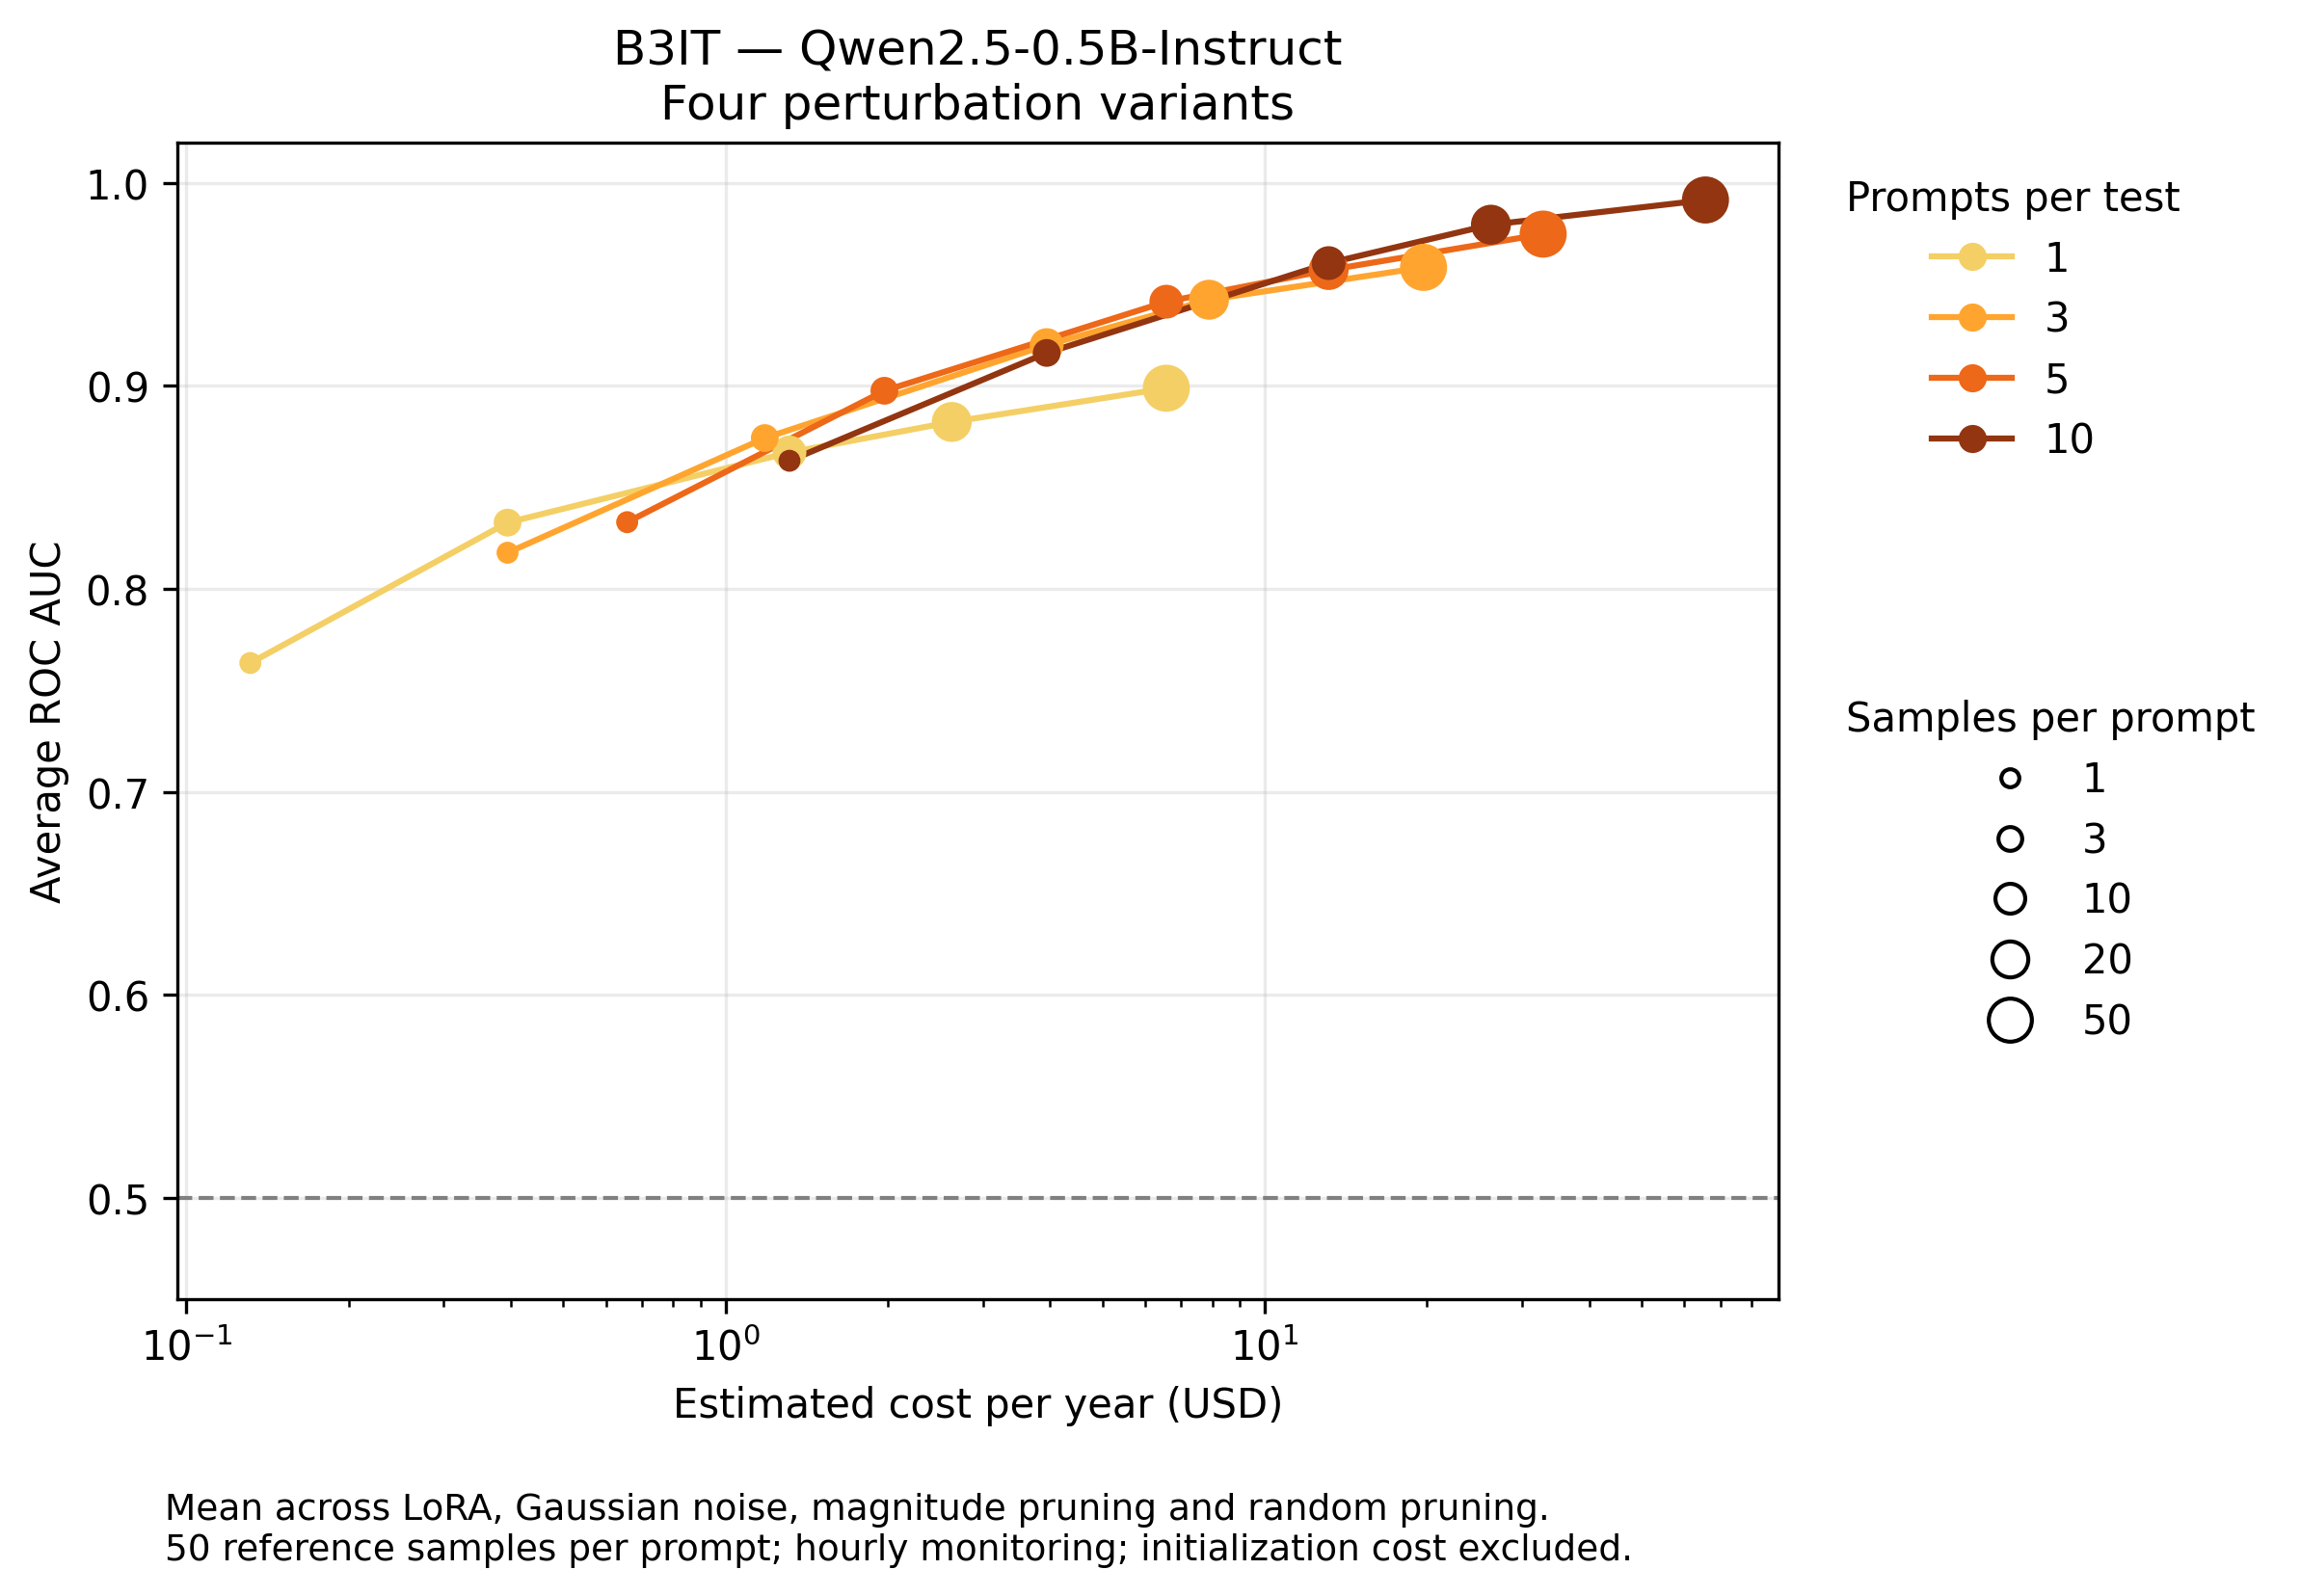

In [ ]:
import os
import subprocess
from pathlib import Path
from IPython.display import display, Image

PROJECT_DIR = Path("/content/b3it-figure1/track-llm-apis")
SAVE_DIR = Path("/content/drive/MyDrive/B3IT_Figure1_TwoModels")
PYTHON = str(PROJECT_DIR / ".venv/bin/python")

plot_code = r'''
import csv
import json
import sys
from collections import defaultdict
from pathlib import Path

import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from track_llm_apis.sampling.common import (
    DataSource,
    load_single_variant_results,
)
from track_llm_apis.sampling.analyze_param_sweeps import (
    compute_auc_from_stats,
)
from track_llm_apis.util import compute_yearly_cost

def save_csv(path, rows):
    with path.open("w", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

def main():
    root = Path(sys.argv[1])
    directory = root / "results" / "figure1_merged"
    output = root / "results" / "figure1"
    output.mkdir(parents=True, exist_ok=True)

    results = load_single_variant_results([directory], DataSource.BI)
    assert len(results) == 80

    grouped = defaultdict(list)
    per_variant = []

    for result in results:
        p = int(result.params["n_prompts"])
        s = int(result.params["detection_samples"])

        auc = compute_auc_from_stats(
            result.h0_stats.stats,
            result.h1_stats.stats,
            sampling=False,
        )

        # Saved token counts already include all prompts and samples
        # in one detection test.
        cost = compute_yearly_cost(
            input_tokens_per_sample=result.h1_stats.input_token_avg / s,
            output_tokens_per_sample=result.h1_stats.output_token_avg / s,
            n_samples=s,
        )

        row = {
            "model": result.model_name,
            "variant": result.variant,
            "n_prompts": p,
            "samples_per_prompt": s,
            "roc_auc": float(auc),
            "yearly_cost_usd": float(cost),
        }
        per_variant.append(row)
        grouped[(p, s)].append(row)

    expected = {
        (p, s)
        for p in [1, 3, 5, 10]
        for s in [1, 3, 10, 20, 50]
    }
    assert set(grouped) == expected

    summary = []
    for (p, s), rows in sorted(grouped.items()):
        assert len(rows) == 4
        assert len({r["variant"] for r in rows}) == 4
        assert np.allclose(
            [r["yearly_cost_usd"] for r in rows],
            rows[0]["yearly_cost_usd"],
        )

        summary.append({
            "n_prompts": p,
            "samples_per_prompt": s,
            "mean_roc_auc": float(np.mean([r["roc_auc"] for r in rows])),
            "yearly_cost_usd": rows[0]["yearly_cost_usd"],
            "number_of_variants": 4,
        })

    save_csv(output / "figure1_per_variant.csv", per_variant)
    save_csv(output / "figure1_summary.csv", summary)

    colors = {
        1: "#f4cf65",
        3: "#ffa52f",
        5: "#ed6818",
        10: "#923510",
    }
    sizes = {1: 20, 3: 35, 10: 55, 20: 80, 50: 115}

    fig, ax = plt.subplots(figsize=(9, 5.8))
    fig.subplots_adjust(right=0.74, bottom=0.19)

    for p, color in colors.items():
        rows = sorted(
            [r for r in summary if r["n_prompts"] == p],
            key=lambda r: r["samples_per_prompt"],
        )
        x = [r["yearly_cost_usd"] for r in rows]
        y = [r["mean_roc_auc"] for r in rows]
        ax.plot(x, y, color=color, linewidth=1.5)
        ax.scatter(
            x, y,
            s=[sizes[r["samples_per_prompt"]] for r in rows],
            color=color,
            zorder=3,
        )

    ax.set_xscale("log")
    ax.set_ylim(0.45, 1.02)
    ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
    ax.set_xlabel("Estimated cost per year (USD)")
    ax.set_ylabel("Average ROC AUC")
    ax.set_title("B3IT — Qwen2.5-0.5B-Instruct\nFour perturbation variants")
    ax.grid(True, which="major", alpha=0.25)

    prompt_legend = ax.legend(
        handles=[
            Line2D([0], [0], color=c, marker="o", label=str(p))
            for p, c in colors.items()
        ],
        title="Prompts per test",
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
        frameon=False,
    )
    ax.add_artist(prompt_legend)

    ax.legend(
        handles=[
            Line2D(
                [0], [0], linestyle="",
                marker="o", markerfacecolor="none",
                markeredgecolor="black",
                markersize=np.sqrt(size), label=str(s),
            )
            for s, size in sizes.items()
        ],
        title="Samples per prompt",
        loc="upper left",
        bbox_to_anchor=(1.02, 0.55),
        frameon=False,
    )

    fig.text(
        0.12, 0.035,
        "Mean across LoRA, Gaussian noise, magnitude pruning and random pruning.\n"
        "50 reference samples per prompt; hourly monitoring; initialization cost excluded.",
        fontsize=9,
    )

    for extension in ["png", "pdf"]:
        fig.savefig(
            output / f"figure1_qwen.{extension}",
            dpi=300,
            bbox_inches="tight",
        )
    plt.close(fig)

    print("Prompts | Samples | Mean ROC AUC | Annual cost")
    for row in summary:
        print(
            f'{row["n_prompts"]:7d} | '
            f'{row["samples_per_prompt"]:7d} | '
            f'{row["mean_roc_auc"]:.4f}       | '
            f'${row["yearly_cost_usd"]:.3f}'
        )

    print("\nFigure 1 and both CSV tables saved to:", output)

if __name__ == "__main__":
    main()
'''

script = PROJECT_DIR / "src/track_llm_apis/plot_figure1.py"
compile(plot_code, str(script), "exec")
script.write_text(plot_code)

backup_dir = SAVE_DIR / "code" / "analysis"
backup_dir.mkdir(parents=True, exist_ok=True)
(backup_dir / script.name).write_text(plot_code)

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"

result = subprocess.run(
    [PYTHON, "-u", "-m", "track_llm_apis.plot_figure1", str(SAVE_DIR)],
    cwd=PROJECT_DIR,
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
)

print(result.stdout)
(SAVE_DIR / "logs" / "figure1_plot.log").write_text(result.stdout)
assert result.returncode == 0, "Plotting failed; share the error."

display(Image(
    filename=str(SAVE_DIR / "results" / "figure1" / "figure1_qwen.png")
))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved: /content/drive/MyDrive/B3IT_Figure1_TwoModels/results/figure1/figure1_qwen_paper_axis.png
Saved: /content/drive/MyDrive/B3IT_Figure1_TwoModels/results/figure1/figure1_qwen_paper_axis.pdf


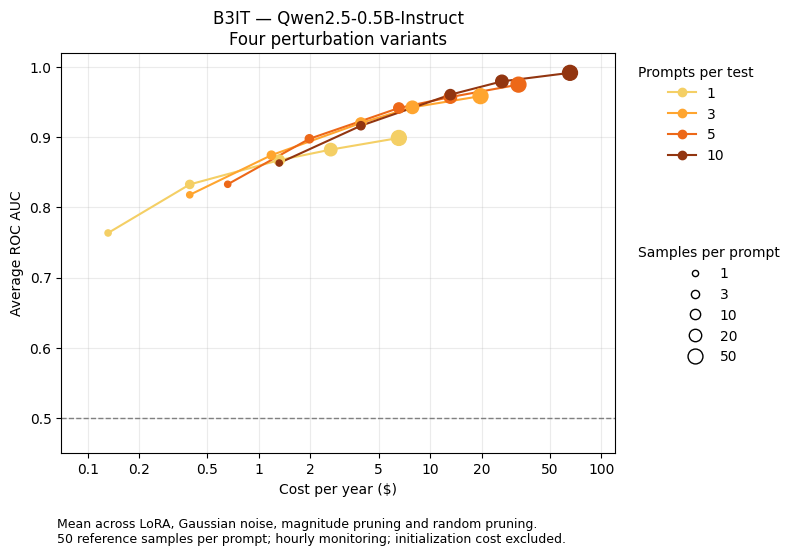

In [ ]:
from google.colab import drive
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import NullLocator

drive.mount("/content/drive")

folder = Path(
    "/content/drive/MyDrive/B3IT_Figure1_TwoModels/results/figure1"
)
csv_path = folder / "figure1_summary.csv"
assert csv_path.exists(), f"Saved results not found: {csv_path}"

df = pd.read_csv(csv_path)
assert len(df) == 20, "Expected 20 parameter combinations."

colors = {1: "#f4cf65", 3: "#ffa52f", 5: "#ed6818", 10: "#923510"}
sizes = {1: 20, 3: 35, 10: 55, 20: 80, 50: 115}

fig, ax = plt.subplots(figsize=(9, 5.8))
fig.subplots_adjust(right=0.74, bottom=0.19)

for prompts, color in colors.items():
    rows = df[df["n_prompts"] == prompts].sort_values("samples_per_prompt")
    ax.plot(
        rows["yearly_cost_usd"], rows["mean_roc_auc"],
        color=color, linewidth=1.5,
    )
    ax.scatter(
        rows["yearly_cost_usd"], rows["mean_roc_auc"],
        s=[sizes[int(s)] for s in rows["samples_per_prompt"]],
        color=color, zorder=3,
    )

# Same logarithmic tick sequence as the paper.
ticks = [0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50, 100]
ax.set_xscale("log")
ax.set_xticks(ticks)
ax.set_xticklabels([str(t) for t in ticks])
ax.xaxis.set_minor_locator(NullLocator())
ax.set_xlim(0.07, 120)

ax.set_ylim(0.45, 1.02)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Cost per year ($)")
ax.set_ylabel("Average ROC AUC")
ax.set_title("B3IT — Qwen2.5-0.5B-Instruct\nFour perturbation variants")
ax.grid(True, which="major", alpha=0.25)

legend = ax.legend(
    handles=[
        Line2D([0], [0], color=c, marker="o", label=str(p))
        for p, c in colors.items()
    ],
    title="Prompts per test",
    loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False,
)
ax.add_artist(legend)

ax.legend(
    handles=[
        Line2D(
            [0], [0], linestyle="", marker="o",
            markerfacecolor="none", markeredgecolor="black",
            markersize=np.sqrt(size), label=str(s),
        )
        for s, size in sizes.items()
    ],
    title="Samples per prompt",
    loc="upper left", bbox_to_anchor=(1.02, 0.55), frameon=False,
)

fig.text(
    0.12, 0.035,
    "Mean across LoRA, Gaussian noise, magnitude pruning and random pruning.\n"
    "50 reference samples per prompt; hourly monitoring; initialization cost excluded.",
    fontsize=9,
)

for extension in ["png", "pdf"]:
    destination = folder / f"figure1_qwen_paper_axis.{extension}"
    fig.savefig(destination, dpi=300, bbox_inches="tight")
    print("Saved:", destination)

plt.show()
plt.close(fig)